# LAB 05 — Sequence Models: RNN, LSTM and GRU (IMDb Sentiment)

**Chủ đề:** From Static Representations to Sequential Modeling
**Dataset:** [IMDb](https://huggingface.co/datasets/stanfordnlp/imdb) — sentiment `positive` / `negative`
(cùng dataset, cùng split, cùng tokenizer với LAB 04 → so sánh trực tiếp được với baseline TF-IDF + LR)

```
Text → Token sequence → Word embeddings → RNN / LSTM / GRU → Hidden state h_T → Linear → Prediction
```

| Notebook | Mục trong đề | Nội dung |
|---|---|---|
| 0 | — | Setup |
| 1 | §11 | Experiment 1 — Dataset inspection |
| 2 | §11 | Train / Validation / Test split |
| 3 | §12 | Tokenization, vocabulary, padding / truncation |
| 4 | §5, §8, §9, §14 | Core implementation — Simple RNN cell (+ minh họa word order, vanishing gradient) |
| 5 | §19 | Model & training loop dùng chung |
| 6 | §15 | Experiment 3 — Baseline TF-IDF + LR vs RNN |
| 7 | §19, §23 | Experiment 4 — RNN vs LSTM vs GRU + learning curves |
| 8 | §13, §20 | Experiment 2 & 5 — max_length / padding / truncation |
| 9 | §21 | Experiment 6 — Long-range dependency |
| 10 | §22 | Evaluation & confusion matrix |
| 11 | §24 | Error analysis |
| 12 | §25 | So sánh với LAB 04 |
| 13 | §26 | Application — sentiment classifier hoàn chỉnh |
| 14 | §29 | Tổng hợp → `results.csv` |

Phần của đề **không** nằm trong notebook: §6–9, §17 → `calculations.md` · §10 → `prediction.md`
(phải ghi **trước** khi xem kết quả) · §24 phân tích → `error_analysis.md` · reflection → `reflection.md` ·
§27 AI policy → `README.md` · §28 vấn đáp.

Các ô **✍️ Tự trả lời** là phần diễn giải / phân tích sinh viên tự viết (theo AI policy, mục 27).

## 0. Setup

In [1]:
import copy
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from torch.nn.utils.rnn import pack_padded_sequence

import preprocessing as pp
from rnn_cell import SimpleRNNCell, compare_with_torch

SEED = pp.SEED
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = False
pd.set_option("display.max_colwidth", 120)

# Cấu hình dùng chung — GIỮ CỐ ĐỊNH cho mọi model; chỉ thay recurrent architecture hoặc max_length
MAX_VOCAB = 20_000    # top 20k token của train (+ <pad>, <unk>)
EMB_DIM = 100
HIDDEN = 128
DROPOUT = 0.3         # trên h_T trước lớp Linear
BATCH_SIZE = 64
LR = 1e-3             # Adam
EPOCHS = 8
CLIP = 5.0            # gradient clipping theo norm (chống exploding gradient)
MAX_LEN = 200         # max_length chính cho Experiment 3, 4, 6 (xem mục 1.3)
MAX_LENS = [50, 100, 200]
ARCHS = ["RNN", "LSTM", "GRU"]
FIXED_ARCH = "LSTM"   # architecture cố định cho Experiment 5


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


print(f"PyTorch {torch.__version__} | device: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

PyTorch 2.14.1+cu126 | device: cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)


## 1. Experiment 1 — Dataset inspection (Đề §11)

Chưa train model ở bước này. Kiểm tra: số samples, số classes, class distribution, document length
(min / median / mean / max), duplicate documents, missing text, missing labels.

In [2]:
raw_train, raw_test = pp.load_imdb()
print(f"Train: {len(raw_train):,} samples | Test: {len(raw_test):,} samples | Tổng: {len(raw_train) + len(raw_test):,}")
raw_train.head()

Train: 25,000 samples | Test: 25,000 samples | Tổng: 50,000


,text,label
0,I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first...,0
1,"""I Am Curious: Yellow"" is a risible and pretentious steaming pile. It doesn't matter what one's political views are ...",0
2,If only to avoid making this type of film in the future. This film is interesting as an experiment but tells no coge...,0
3,"This film was probably inspired by Godard's Masculin, féminin and I urge you to see that film instead.<br /><br />Th...",0
4,"Oh, brother...after hearing about this ridiculous film for umpteen years all I can think of is that old Peggy Lee so...",0


### 1.1 Số classes & class distribution

Số classes:

 2 -> {0: 'negative', 1: 'positive'}


train              test           
          Count Percentage  Count Percentage
label                                       
negative  12500       50.0  12500       50.0
positive  12500       50.0  12500       50.0

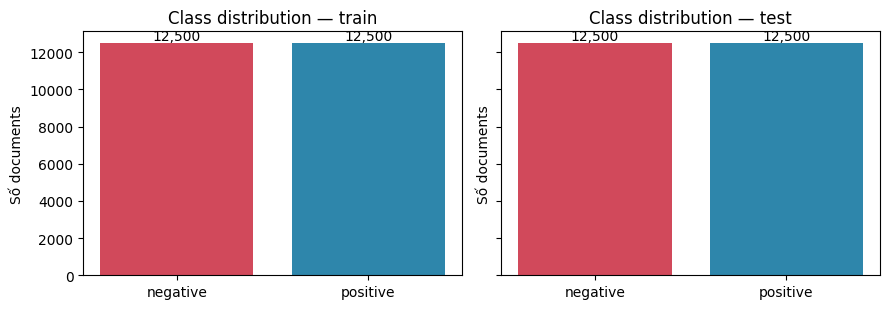

In [3]:
print("Số classes:", raw_train["label"].nunique(), "->", pp.LABEL_NAMES)
display(pd.concat({"train": pp.class_distribution(raw_train["label"]),
                   "test": pp.class_distribution(raw_test["label"])}, axis=1))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, (name, df) in zip(axes, [("train", raw_train), ("test", raw_test)]):
    counts = df["label"].map(pp.LABEL_NAMES).value_counts().sort_index()
    ax.bar(counts.index, counts.values, color=["#d1495b", "#2e86ab"])
    for x, v in enumerate(counts.values):
        ax.text(x, v, f"{v:,}", ha="center", va="bottom")
    ax.set_title(f"Class distribution — {name}")
    ax.set_ylabel("Số documents")
plt.tight_layout()
plt.show()

### 1.2 Missing text / missing labels

In [4]:
def missing_report(df):
    text = df["text"]
    return pd.Series({
        "missing text (NaN)": text.isna().sum(),
        "text rỗng / chỉ khoảng trắng": (text.fillna("").str.strip() == "").sum(),
        "missing label (NaN)": df["label"].isna().sum(),
        "label ngoài {0, 1}": (~df["label"].isin([0, 1])).sum(),
    })


pd.DataFrame({"train": missing_report(raw_train), "test": missing_report(raw_test)})

,train,test
missing text (NaN),0,0
text rỗng / chỉ khoảng trắng,0,0
missing label (NaN),0,0
"label ngoài {0, 1}",0,0


### 1.3 Sequence length (số tokens sau `pp.tokenize`)

Sequence length ở đây = số token mà model sẽ đọc (cùng tokenizer với LAB 04: lowercase, bỏ HTML, bỏ dấu câu,
giữ contraction như `don't`).

In [5]:
for df in (raw_train, raw_test):
    df["tokens"] = df["text"].map(pp.tokenize)
    df["n_tokens"] = df["tokens"].map(len)


def length_stats(s):
    return pd.Series({"min": s.min(), "median": s.median(), "mean": s.mean(), "p75": s.quantile(.75),
                      "p90": s.quantile(.90), "p95": s.quantile(.95), "max": s.max()})


pd.DataFrame({"train": length_stats(raw_train["n_tokens"]),
              "test": length_stats(raw_test["n_tokens"]),
              "train / negative": length_stats(raw_train.loc[raw_train["label"] == 0, "n_tokens"]),
              "train / positive": length_stats(raw_train.loc[raw_train["label"] == 1, "n_tokens"])}).T.round(1)

,min,median,mean,p75,p90,p95,max
train,10.0,174.0,233.6,283.0,457.0,598.0,2473.0
test,6.0,172.0,228.3,276.0,443.0,582.0,2246.0
train / negative,10.0,174.0,230.6,278.0,441.0,578.0,1522.0
train / positive,12.0,174.0,236.6,290.0,471.0,619.0,2473.0


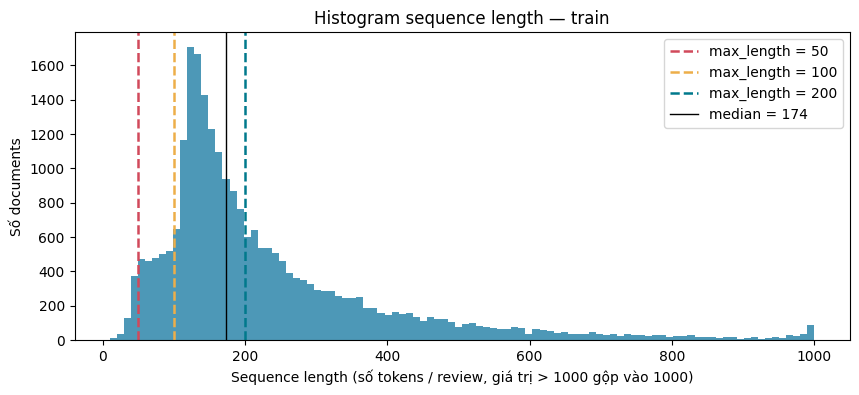

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(raw_train["n_tokens"].clip(upper=1000), bins=100, color="#2e86ab", alpha=0.85)
for L, c in zip(MAX_LENS, ["#d1495b", "#edae49", "#00798c"]):
    ax.axvline(L, color=c, ls="--", lw=1.8, label=f"max_length = {L}")
med = raw_train["n_tokens"].median()
ax.axvline(med, color="k", lw=1, label=f"median = {med:.0f}")
ax.set_xlabel("Sequence length (số tokens / review, giá trị > 1000 gộp vào 1000)")
ax.set_ylabel("Số documents")
ax.set_title("Histogram sequence length — train")
ax.legend()
plt.show()

Nếu cắt mọi review về `max_length`, bao nhiêu review còn nguyên và bao nhiêu % token được giữ lại?

In [7]:
coverage = pd.DataFrame([{"max_length": L,
                          "% review không bị cắt": 100 * (raw_train["n_tokens"] <= L).mean(),
                          "% tokens retained": pp.pct_tokens_retained(raw_train["n_tokens"], L)}
                         for L in [30, 50, 100, 200, 300, 400, 600]]).set_index("max_length")
coverage.round(1)

,% review không bị cắt,% tokens retained
max_length,,
30,0.2,12.8
50,2.4,21.3
100,12.1,41.2
200,58.6,68.2
300,77.2,81.5
400,86.6,89.0
600,95.1,96.2


### 1.4 Duplicate documents

So sánh sau khi chuẩn hóa nhẹ (`pp.clean_text`). Review xuất hiện ở **cả train và test** là leakage, cần bỏ khỏi train.

In [8]:
for df in (raw_train, raw_test):
    df["norm"] = df["text"].map(pp.clean_text)

train_test_overlap = set(raw_train["norm"]) & set(raw_test["norm"])
pd.Series({
    "duplicate trong train": raw_train["norm"].duplicated().sum(),
    "duplicate trong test": raw_test["norm"].duplicated().sum(),
    "review có ở cả train và test": len(train_test_overlap),
    "nhóm duplicate trong train có label mâu thuẫn": raw_train.groupby("norm")["label"].nunique().gt(1).sum(),
}).to_frame("count")

,count
duplicate trong train,98
duplicate trong test,201
review có ở cả train và test,123
nhóm duplicate trong train có label mâu thuẫn,0


> ✍️ **Tự trả lời:** Nếu phải chọn `max_length`, nên chọn dựa trên thông tin nào? (dựa vào histogram, bảng % review không bị cắt / % tokens retained, và chi phí tính toán, không chỉ "chạy nhanh")
>
> Nên chọn dựa trên phân phối độ dài review và lượng thông tin giữ lại được. Review ở train có median 174 token, mean 233.6, p90 khoảng 457 và dài nhất tới 2,473 token, tức là phân phối lệch phải với đuôi rất dài. Với max_length = 200, 58.6% review không bị cắt và giữ được 68.2% tổng số token. Nếu giảm xuống 50 hoặc 30 thì chỉ còn 21.3% và 12.8% số token, mất phần lớn nội dung. Nếu tăng lên 400 thì giữ được 89.0% token nhưng chuỗi dài gấp đôi, thời gian train và memory cũng tăng theo, trong khi RNN vốn đã khó dùng thông tin ở xa. Vì vậy 200 là mức cân bằng hợp lý: gần median, hơn một nửa số review được đọc trọn vẹn, chi phí vẫn chấp nhận được.

## 2. Train / Validation / Test split

Giống hệt LAB 04 (cùng seed) để baseline so sánh được:
- **Test:** giữ nguyên test chuẩn của IMDb (25k) — chỉ dùng để báo cáo kết quả cuối.
- **Train gốc:** bỏ duplicate và review trùng với test, rồi chia **80% train / 20% validation** (stratified).
- **Validation:** chọn epoch tốt nhất (min validation loss) và chọn `C` cho baseline. Không chọn gì dựa trên test.

In [9]:
conflicting = raw_train.groupby("norm")["label"].transform("nunique") > 1
clean_train = (raw_train[~conflicting]
               .drop_duplicates("norm")
               .loc[lambda d: ~d["norm"].isin(train_test_overlap)]
               .reset_index(drop=True))
print(f"Train gốc: {len(raw_train):,} -> sau khi làm sạch: {len(clean_train):,}")

train_df, val_df = pp.split_train_val(clean_train, val_size=0.2)
test_df = raw_test.reset_index(drop=True)

assert not set(train_df["norm"]) & set(val_df["norm"]), "train/val bị trùng"
assert not set(train_df["norm"]) & set(test_df["norm"]), "train/test bị trùng"

y_train, y_val, y_test = (df["label"].to_numpy() for df in (train_df, val_df, test_df))

pd.concat({name: pp.class_distribution(y)
           for name, y in [("train", y_train), ("validation", y_val), ("test", y_test)]}, axis=1)

Train gốc: 25,000 -> sau khi làm sạch: 24,779


train            validation              test           
         Count Percentage      Count Percentage  Count Percentage
positive  9954      50.21       2489      50.22  12500       50.0
negative  9869      49.79       2467      49.78  12500       50.0

## 3. Tokenization, vocabulary, padding / truncation (Đề §12)

```
Raw text → Tokenizer → Token IDs → Padding / truncation → Embedding → RNN/LSTM/GRU
```

- Vocabulary chỉ build trên **train** (top 20,000 token, tần suất ≥ 2). Id `0 = <pad>`, `1 = <unk>`.
- **Truncation** (mặc định `head`): review dài hơn `max_length` bị cắt, chỉ giữ `max_length` token đầu.
- **Padding**: review ngắn hơn được thêm `<pad>` vào cuối để cùng độ dài trong một batch.

In [10]:
vocab = pp.Vocabulary(train_df["tokens"], max_size=MAX_VOCAB, min_freq=2)
VOCAB_SIZE = len(vocab)


def unk_rate(token_lists):
    total = sum(len(t) for t in token_lists)
    unk = sum(tok not in vocab.stoi for toks in token_lists for tok in toks)
    return 100 * unk / total


print(f"Số token khác nhau trong train          : {len(vocab.counts):,}")
print(f"Vocabulary (top {MAX_VOCAB:,} + <pad>, <unk>)   : {VOCAB_SIZE:,}")
print(f"Tần suất thấp nhất còn được giữ          : {vocab.counts[vocab.itos[-1]]}")
pd.Series({name: unk_rate(df["tokens"]) for name, df in
           [("train", train_df), ("validation", val_df), ("test", test_df)]}).round(2).to_frame("% token -> <unk>")

Số token khác nhau trong train          : 73,542
Vocabulary (top 20,000 + <pad>, <unk>)   : 20,002
Tần suất thấp nhất còn được giữ          : 8


,% token -> <unk>
train,2.59
validation,2.92
test,3.33


In [11]:
s = "I really like this movie"
toks = pp.tokenize(s)
ids = vocab.encode(toks)
padded, n = pp.pad_truncate(ids, 8)
print("Raw text            :", s)
print("Tokens              :", toks)
print("Token IDs           :", ids)
print("Padding -> 8        :", padded.tolist(), "| length thật =", n)
print("Truncation -> 3     :", pp.pad_truncate(ids, 3)[0].tolist(), "(head: giữ đầu) |",
      pp.pad_truncate(ids, 3, "tail")[0].tolist(), "(tail: giữ cuối)")
print("Decode (bỏ <pad>)   :", vocab.decode(padded))

Raw text            : I really like this movie
Tokens              : ['i', 'really', 'like', 'this', 'movie']
Token IDs           : [10, 63, 37, 11, 17]
Padding -> 8        : [10, 63, 37, 11, 17, 0, 0, 0] | length thật = 5
Truncation -> 3     : [10, 63, 37] (head: giữ đầu) | [37, 11, 17] (tail: giữ cuối)
Decode (bỏ <pad>)   : ['i', 'really', 'like', 'this', 'movie']


**Padding không phải thông tin ngôn ngữ.** Embedding của `<pad>` là vector 0 (`padding_idx`), nhưng nếu đưa cả
`<pad>` vào LSTM thì hidden state vẫn bị cập nhật thêm 3 bước (do bias và $W_{hh} h_{t-1}$).
`pack_padded_sequence` báo cho LSTM độ dài thật nên $h_T$ được lấy đúng tại token thật cuối cùng.
Mọi model trong notebook này đều dùng cách này.

In [12]:
set_seed()
emb_demo = nn.Embedding(VOCAB_SIZE, 8, padding_idx=pp.PAD)
lstm_demo = nn.LSTM(8, 4, batch_first=True)
ids_nopad = torch.tensor([ids])                  # 5 token thật
ids_pad = torch.from_numpy(padded)[None]         # 5 token thật + 3 <pad>
with torch.no_grad():
    _, (h_ref, _) = lstm_demo(emb_demo(ids_nopad))
    _, (h_pad, _) = lstm_demo(emb_demo(ids_pad))
    _, (h_pack, _) = lstm_demo(pack_padded_sequence(emb_demo(ids_pad), torch.tensor([n]), batch_first=True))
print("embedding(<pad>)                         :", emb_demo.weight[pp.PAD].tolist())
print("h_T — không padding                      :", h_ref[0, 0].numpy().round(4))
print("h_T — có padding, đưa cả <pad> vào LSTM  :", h_pad[0, 0].numpy().round(4),
      f"| sai khác {(h_pad - h_ref).abs().max():.4f}")
print("h_T — có padding + pack_padded_sequence  :", h_pack[0, 0].numpy().round(4),
      f"| sai khác {(h_pack - h_ref).abs().max():.4f}")

embedding(<pad>)                         : [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
h_T — không padding                      : [-0.2319 -0.1277 -0.1459  0.1996]
h_T — có padding, đưa cả <pad> vào LSTM  : [-0.1621 -0.1637 -0.4007  0.202 ] | sai khác 0.2548
h_T — có padding + pack_padded_sequence  : [-0.2319 -0.1277 -0.1459  0.1996] | sai khác 0.0000


> ✍️ **Tự trả lời:** Phân biệt padding và truncation. Vì sao padding không phải là thông tin ngôn ngữ thực sự, còn truncation thì làm mất thông tin thật?
>
> Padding là thêm token `<pad>` vào cuối các review ngắn để mọi review trong batch có cùng độ dài. Truncation là cắt bớt những review dài hơn max_length.
>
> `<pad>` không phải là từ người viết đã viết, nó chỉ là chỗ trống để xếp batch thành ma trận. Embedding của `<pad>` luôn bằng 0 (`padding_idx = 0`), và khi dùng `pack_padded_sequence` thì model dừng ở token thật cuối cùng nên $h_T$ không đổi (sai khác 0.0000). Nếu đưa cả `<pad>` vào LSTM mà không pack thì $h_T$ lệch 0.2548, tức là padding chỉ gây nhiễu chứ không thêm thông tin gì.
>
> Ngược lại, truncation bỏ đi những từ thật của review. Với max_length = 200, 41.4% review bị cắt và mất 31.8% số token. Phần bị cắt có thể chính là câu kết luận như "I cannot recommend it", nên truncation làm mất thông tin thật.

## 4. Core implementation — Simple RNN cell (Đề §14)

Cài đặt trong `rnn_cell.py` bằng NumPy:

$$a_t = W_{xh}x_t + W_{hh}h_{t-1} + b_h, \qquad h_t = \tanh(a_t)$$

```
x_t ──► W_xh ──┐
               (+) ◄── W_hh ◄── h_(t-1)
                │
              tanh
                │
               h_t ──► (sang bước t+1)
```

### 4.1 Test với input nhỏ và so sánh với PyTorch
Copy cùng trọng số vào `torch.nn.RNNCell` và `torch.nn.RNN`. Lưu ý PyTorch dùng **hai** bias
($b_{ih} + b_{hh}$), tương đương một $b_h$.

In [13]:
diffs = compare_with_torch(input_size=3, hidden_size=2, seq_len=4, batch_size=2)
assert all(d < 1e-10 for d in diffs.values())

Input nhỏ: seq_len=4, batch=2, input_size=3, hidden_size=2
Số tham số: W_xh (2, 3) + W_hh (2, 2) + b_h (2,) = 12
  t=1: h_t[sample 0] = [ 0.179716 -0.394488]
  t=2: h_t[sample 0] = [ 0.633251 -0.948604]
  t=3: h_t[sample 0] = [ 0.581015 -0.448106]
  t=4: h_t[sample 0] = [ 0.209479 -0.684594]
Sai khác tuyệt đối lớn nhất:
  SimpleRNNCell vs nn.RNNCell (mọi timestep)                 1.11e-16
  SimpleRNNCell vs nn.RNN (mọi timestep)                     1.11e-16
  h_T của mình vs h_n của nn.RNN                             8.33e-17
  nn.RNNCell (2 bias) -> SimpleRNNCell (b_h = b_ih + b_hh)   5.55e-17


### 4.2 Kiểm tra Bài 1 (§6)
Chỉ dùng để **đối chiếu** sau khi đã tự tính tay trong `calculations.md`.

In [14]:
cell_b1 = SimpleRNNCell.from_weights(W_xh=[[0.5, 0.2], [0.1, 0.4]], W_hh=[[0.3, 0.1], [0.2, 0.5]], b_h=[0, 0])
x_t, h_prev = np.array([1.0, 0.0]), np.array([0.5, 0.2])
print("W_xh x_t     =", cell_b1.W_xh @ x_t)
print("W_hh h_(t-1) =", cell_b1.W_hh @ h_prev)
print("a_t          =", cell_b1.preactivation(x_t, h_prev).round(4))
print("h_t          =", cell_b1.forward(x_t, h_prev).round(4))

W_xh x_t     = [0.5 0.1]
W_hh h_(t-1) = [0.17 0.2 ]
a_t          = [0.67 0.3 ]
h_t          = [0.585  0.2913]


### 4.3 Word order (Bài 3, §8): `"dog bites man"` vs `"man bites dog"`
Cùng embedding (ngẫu nhiên, cố định) và cùng một cell. Average embedding của hai câu **bằng nhau**;
hidden state cuối $h_T$ của RNN thì không.

In [15]:
rng = np.random.default_rng(SEED)
emb_toy = {w: rng.normal(size=4) for w in ["dog", "bites", "man"]}
cell_toy = SimpleRNNCell(input_size=4, hidden_size=3, seed=SEED)

for s in ["dog bites man", "man bites dog"]:
    xs = np.stack([emb_toy[w] for w in s.split()])
    hs = cell_toy.forward_sequence(xs)
    print(f"{s!r}")
    print(f"   average embedding = {xs.mean(axis=0).round(4)}")
    for w, h in zip(s.split(), hs):
        print(f"   sau {w!r:8}: h_t = {h.round(4)}")

'dog bites man'
   average embedding = [-0.5544 -1.0651  0.5859  0.4674]
   sau 'dog'   : h_t = [0.483  0.351  0.6256]
   sau 'bites' : h_t = [-0.4947  0.2275  0.9237]
   sau 'man'   : h_t = [0.3545 0.3003 0.7088]
'man bites dog'
   average embedding = [-0.5544 -1.0651  0.5859  0.4674]
   sau 'man'   : h_t = [0.4039 0.5406 0.6423]
   sau 'bites' : h_t = [-0.4509  0.2543  0.9243]
   sau 'dog'   : h_t = [0.4514 0.059  0.7053]


### 4.4 Vanishing / exploding gradient (§9) — minh họa bằng số

$\frac{\partial h_T}{\partial h_{T-d}} = \prod_k \frac{\partial h_k}{\partial h_{k-1}}$ với
$\frac{\partial h_k}{\partial h_{k-1}} = \mathrm{diag}(1 - h_k^2)\,W_{hh}$.
Tính norm của tích này theo khoảng cách $d$ với cell ở trên, $W_{hh} = s \cdot Q$ ($Q$ trực giao, nên mọi
singular value của $W_{hh}$ bằng $s$). Bên phải: bỏ `tanh` (RNN tuyến tính) để tách riêng ảnh hưởng của $W_{hh}$.

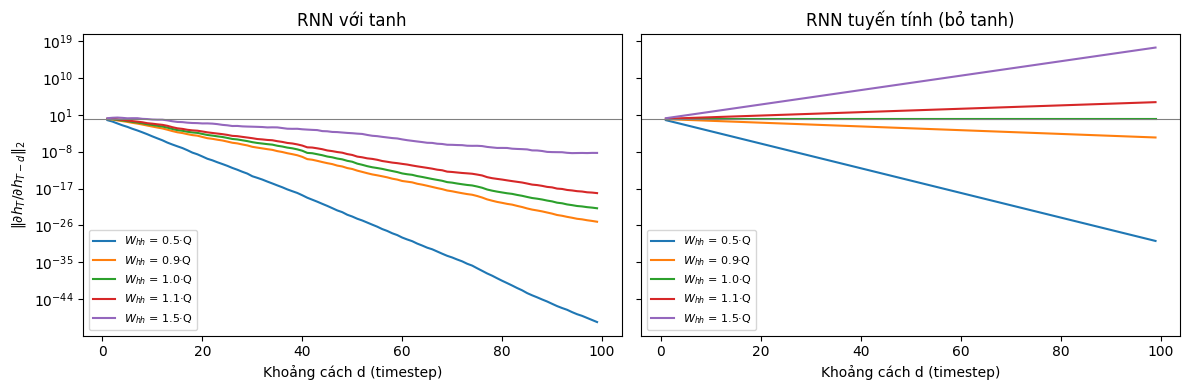

d=1       d=10          d=50          d=99
tanh RNN   0.5  0.499976   0.000054  1.455707e-24  2.465296e-50
           0.9  0.899850   0.013696  5.941725e-13  7.823664e-26
           1.0  0.999519   0.033259  3.511209e-11  1.522836e-22
           1.1  1.096518   0.069171  1.590418e-09  7.638044e-19
           1.5  1.499895   0.714725  3.259060e-04  4.992414e-09
linear RNN 0.5  0.500000   0.000977  8.881784e-16  1.577722e-30
           0.9  0.900000   0.348678  5.153775e-03  2.951267e-05
           1.0  1.000000   1.000000  1.000000e+00  1.000000e+00
           1.1  1.100000   2.593742  1.173909e+02  1.252783e+04
           1.5  1.500000  57.665039  6.376215e+08  2.710408e+17

In [16]:
def jacobian_norms(cell, xs, linear=False):
    # ||∂h_T/∂h_(T-d)||_2 với d = 1..T-1: nhân dần các Jacobian diag(1 - h_k^2) · W_hh từ cuối về đầu
    h, hs = cell.init_hidden(), []
    for x_t in xs:
        a = cell.preactivation(x_t, h)
        h = a if linear else np.tanh(a)
        hs.append(h)
    J, norms = np.eye(cell.hidden_size), []
    for k in range(len(xs) - 1, 0, -1):
        local = cell.W_hh if linear else (1 - hs[k] ** 2)[:, None] * cell.W_hh
        J = J @ local
        norms.append(np.linalg.norm(J, 2))
    return np.array(norms)


H_DEMO, IN_DEMO, T_DEMO = 32, 16, 100
rng = np.random.default_rng(SEED)
Q, _ = np.linalg.qr(rng.normal(size=(H_DEMO, H_DEMO)))
W_xh_demo = rng.normal(size=(H_DEMO, IN_DEMO)) * 0.3
xs_demo = rng.normal(size=(T_DEMO, IN_DEMO))
SCALES = [0.5, 0.9, 1.0, 1.1, 1.5]

jac = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, linear in zip(axes, [False, True]):
    for s in SCALES:
        norms = jacobian_norms(SimpleRNNCell.from_weights(W_xh_demo, s * Q), xs_demo, linear)
        jac[("tanh RNN" if not linear else "linear RNN", s)] = norms
        ax.semilogy(np.arange(1, T_DEMO), norms, label=f"$W_{{hh}}$ = {s}·Q")
    ax.axhline(1, color="gray", lw=0.8)
    ax.set_title("RNN tuyến tính (bỏ tanh)" if linear else "RNN với tanh")
    ax.set_xlabel("Khoảng cách d (timestep)")
    ax.legend(fontsize=8)
axes[0].set_ylabel(r"$\|\partial h_T / \partial h_{T-d}\|_2$")
plt.tight_layout()
plt.show()

pd.DataFrame({k: v[[0, 9, 49, 98]] for k, v in jac.items()}, index=["d=1", "d=10", "d=50", "d=99"]).T

> ✍️ **Tự trả lời:** Giải thích computation graph của RNN cell: vai trò của $W_{xh}$, $W_{hh}$, $h_{t-1}$ và tanh. Vì sao cùng một bộ trọng số được dùng ở mọi timestep?
>
> Ở mỗi bước: $a_t = W_{xh}x_t + W_{hh}h_{t-1} + b_h$, sau đó $h_t = \tanh(a_t)$.
> - $W_{xh}$ chiếu input hiện tại (embedding của token $x_t$) vào không gian hidden.
> - $h_{t-1}$ là "bộ nhớ", tóm tắt những gì model đã đọc trước đó.
> - $W_{hh}$ quyết định thông tin cũ được giữ lại và trộn với input mới như thế nào.
> - tanh là hàm phi tuyến, nén giá trị về khoảng (-1, 1) để hidden state không tăng mãi, đồng thời giúp model học được quan hệ phức tạp hơn một tổ hợp tuyến tính.
>
> Cùng một bộ trọng số được dùng ở mọi timestep vì cách xử lý một từ không nên phụ thuộc vào vị trí của nó: "good" ở vị trí 3 hay vị trí 30 đều được xử lý theo cùng một quy tắc, chỉ khác nhau ở $h_{t-1}$. Nhờ vậy số tham số không tăng theo độ dài sequence (cell ở mục 4.1 chỉ có 12 tham số dù seq_len bằng bao nhiêu), và model xử lý được sequence có độ dài bất kỳ.

> ✍️ **Tự trả lời:** Dựa vào hình 4.4: vì sao sequence càng dài, RNN càng khó học dependency ở xa? Exploding gradient xuất hiện khi nào?
>
> Gradient từ $h_T$ về $h_{T-d}$ là tích của d Jacobian $\partial h_k / \partial h_{k-1} = \text{diag}(1 - h_k^2)\,W_{hh}$. Đạo hàm của tanh luôn nhỏ hơn hoặc bằng 1, nên mỗi bước lại làm gradient nhỏ đi. Trong bảng 4.4, với tanh RNN và scale 1.0, norm ở d = 10 chỉ còn 0.033 và ở d = 99 còn khoảng 1e-22. Khoảng cách càng xa thì tích càng nhiều thừa số, tín hiệu từ token ở xa gần như bằng 0, nên model không biết phải chỉnh trọng số thế nào để dùng thông tin đó.
>
> Exploding gradient xuất hiện khi các Jacobian có norm lớn hơn 1 và không bị kìm lại. Với linear RNN, scale 1.1 cho norm ở d = 99 khoảng 1.25e4, scale 1.5 lên tới 2.7e17. Với tanh RNN, đạo hàm tanh kìm lại nên trong hình không bị nổ, nhưng khi train thật vẫn có những lúc gradient rất lớn (gradient norm của RNN có lúc lên 115 ở mục 7), vì vậy cần gradient clipping.

## 5. Model & training loop dùng chung (Đề §19)

```
ids ─► Embedding(20,002 × 100) ─► RNN / LSTM / GRU (hidden 128) ─► h_T ─► Dropout(0.3) ─► Linear(128 → 1) ─► logit
```

- $h_T$ = hidden state tại **token thật cuối cùng** (`pack_padded_sequence`, không tính `<pad>`).
- Binary classification: $P(\text{positive} \mid x) = \sigma(W_{hy}h_T + b_y)$, loss = binary cross-entropy.
- Embedding khởi tạo ngẫu nhiên và học cùng model.
- Mọi model dùng chung: vocabulary, embedding dim, hidden size, batch size, optimizer (Adam), learning rate,
  số epoch, gradient clipping, seed, split. **Chỉ thay recurrent layer** (hoặc `max_length` ở mục 8).
- Train đủ `EPOCHS` epoch; đánh giá test bằng trọng số của epoch có **validation loss nhỏ nhất**.
- `train_time_s`: chỉ tính thời gian các vòng train (không tính đánh giá validation).
- `grad_norm`: norm của gradient **trước** khi clip — theo dõi exploding gradient.

In [17]:
class SeqClassifier(nn.Module):
    RECURRENT = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}

    def __init__(self, arch, vocab_size, emb_dim=EMB_DIM, hidden=HIDDEN, dropout=DROPOUT):
        super().__init__()
        self.arch = arch
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pp.PAD)
        self.rnn = self.RECURRENT[arch](emb_dim, hidden, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden, 1)

    def from_embeddings(self, emb, lengths):
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, h_n = self.rnn(packed)          # RNN / GRU: h_n | LSTM: (h_n, c_n)
        if isinstance(h_n, tuple):
            h_n = h_n[0]
        return self.fc(self.dropout(h_n[-1])).squeeze(-1)

    def forward(self, ids, lengths):
        return self.from_embeddings(self.embedding(ids), lengths)


def count_params(model):
    return sum(p.numel() for p in model.parameters()), sum(p.numel() for p in model.rnn.parameters())


for arch in ARCHS:
    m = SeqClassifier(arch, VOCAB_SIZE)
    total, rec = count_params(m)
    print(f"{arch:5s}: tổng {total:>9,} tham số | recurrent layer {rec:>7,} | embedding {m.embedding.weight.numel():,}")

RNN  : tổng 2,029,769 tham số | recurrent layer  29,440 | embedding 2,000,200
LSTM : tổng 2,118,089 tham số | recurrent layer 117,760 | embedding 2,000,200
GRU  : tổng 2,088,649 tham số | recurrent layer  88,320 | embedding 2,000,200


In [18]:
ENCODED = {}   # (max_len, truncation) -> {"train": (ids, lengths), "val": ..., "test": ...}
RUNS = {}      # (arch, max_len, truncation) -> kết quả một lần train


def get_data(max_len, truncation="head"):
    key = (max_len, truncation)
    if key not in ENCODED:
        ENCODED[key] = {name: pp.encode_corpus(df["tokens"], vocab, max_len, truncation)
                        for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]}
    return ENCODED[key]


@torch.no_grad()
def predict_logits(model, ids, lengths, batch_size=512):
    model.eval()
    out = []
    for i in range(0, len(ids), batch_size):
        b_ids = torch.as_tensor(ids[i:i + batch_size], device=DEVICE)
        b_len = torch.as_tensor(lengths[i:i + batch_size])
        out.append(model(b_ids, b_len).float().cpu())
    return torch.cat(out).numpy()


def bce(logits, y):
    return nn.functional.binary_cross_entropy_with_logits(torch.as_tensor(logits),
                                                          torch.as_tensor(y, dtype=torch.float32)).item()


def evaluate(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0)}


def train_model(arch, max_len=MAX_LEN, truncation="head", epochs=EPOCHS, verbose=True):
    set_seed()
    data = get_data(max_len, truncation)
    loader = pp.make_loader(*data["train"], y_train, batch_size=BATCH_SIZE, shuffle=True)
    model = SeqClassifier(arch, VOCAB_SIZE).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.BCEWithLogitsLoss()

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
        mem_before = torch.cuda.memory_allocated()
        torch.cuda.reset_peak_memory_stats()
    history, best, train_time = [], None, 0.0
    for epoch in range(1, epochs + 1):
        model.train()
        t0 = time.perf_counter()
        total_loss, n_seen, grad_norms = 0.0, 0, []
        for ids, lengths, y in loader:
            ids, y = ids.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(ids, lengths), y)
            loss.backward()
            grad_norms.append(nn.utils.clip_grad_norm_(model.parameters(), CLIP).item())
            opt.step()
            total_loss += loss.item() * len(y)
            n_seen += len(y)
        epoch_time = time.perf_counter() - t0
        train_time += epoch_time

        val_logits = predict_logits(model, *data["val"])
        val_pred = (val_logits > 0).astype(int)
        history.append({"epoch": epoch, "train_loss": total_loss / n_seen, "val_loss": bce(val_logits, y_val),
                        "val_acc": accuracy_score(y_val, val_pred), "val_f1": f1_score(y_val, val_pred),
                        "grad_norm_mean": np.mean(grad_norms), "grad_norm_max": np.max(grad_norms),
                        "epoch_time_s": epoch_time})
        if best is None or history[-1]["val_loss"] < best["val_loss"]:
            best = {**history[-1], "state": copy.deepcopy(model.state_dict())}
        if verbose:
            h = history[-1]
            print(f"  [{arch} L={max_len} {truncation}] epoch {epoch}: train {h['train_loss']:.4f} | "
                  f"val {h['val_loss']:.4f} | val acc {h['val_acc']:.4f} | {epoch_time:.1f}s")
    peak_mem = (torch.cuda.max_memory_allocated() - mem_before) / 2**20 if DEVICE.type == "cuda" else np.nan

    model.load_state_dict(best["state"])
    test_logits = predict_logits(model, *data["test"])
    y_pred = (test_logits > 0).astype(int)
    total, rec = count_params(model)
    row = {"model": arch, "representation": "Embedding (học cùng model)", "max_len": max_len,
           "truncation": truncation, "pct_tokens_retained": pp.pct_tokens_retained(train_df["n_tokens"], max_len),
           "vocab_size": VOCAB_SIZE, "n_params": total, "n_params_recurrent": rec, "epochs": epochs,
           "best_epoch": best["epoch"], "train_time_s": train_time, "time_per_epoch_s": train_time / epochs,
           "peak_gpu_mem_mb": peak_mem, "best_val_loss": best["val_loss"], "val_f1": best["val_f1"],
           "test_loss": bce(test_logits, y_test), **evaluate(y_test, y_pred)}
    return {"kind": "seq", "model": model, "history": pd.DataFrame(history), "row": row,
            "proba": sigmoid(test_logits), "y_pred": y_pred}


def get_run(arch, max_len=MAX_LEN, truncation="head"):
    key = (arch, max_len, truncation)
    if key not in RUNS:
        RUNS[key] = train_model(arch, max_len, truncation)
    return RUNS[key]


def show(runs, cols=("model", "representation", "max_len", "accuracy", "precision", "recall", "f1",
                     "train_time_s")):
    return pd.DataFrame([r["row"] for r in runs])[list(cols)].round(4)

## 6. Experiment 3 — Baseline TF-IDF + LR vs Simple RNN (Đề §15)

Baseline của LAB 04: TF-IDF (unigram, `min_df=2`) + Logistic Regression, chọn `C` theo F1 trên validation.

In [19]:
C_GRID = [0.01, 0.1, 1, 10, 100]
t0 = time.perf_counter()
tfidf = TfidfVectorizer(**pp.tfidf_params())
Xtr_tfidf = tfidf.fit_transform(train_df["text"])
rep_time = time.perf_counter() - t0
Xva_tfidf, Xte_tfidf = tfidf.transform(val_df["text"]), tfidf.transform(test_df["text"])

best = None
for C in C_GRID:
    t0 = time.perf_counter()
    clf = LogisticRegression(C=C, solver="liblinear", max_iter=1000).fit(Xtr_tfidf, y_train)
    fit_time = time.perf_counter() - t0
    val_f1 = f1_score(y_val, clf.predict(Xva_tfidf))
    if best is None or val_f1 > best["val_f1"]:
        best = {"clf": clf, "C": C, "val_f1": val_f1, "fit_time": fit_time}
lr_tfidf = best["clf"]
proba_tfidf = lr_tfidf.predict_proba(Xte_tfidf)[:, 1]
pred_tfidf = lr_tfidf.predict(Xte_tfidf)

RUN_TFIDF = {"kind": "tfidf", "proba": proba_tfidf, "y_pred": pred_tfidf, "row": {
    "model": "Logistic Regression", "representation": "TF-IDF (unigram)", "max_len": "full", "truncation": "none",
    "pct_tokens_retained": 100.0, "vocab_size": len(tfidf.vocabulary_), "n_params": Xtr_tfidf.shape[1] + 1,
    "n_params_recurrent": 0, "epochs": np.nan, "best_epoch": np.nan, "best_C": best["C"],
    "train_time_s": rep_time + best["fit_time"], "val_f1": best["val_f1"], **evaluate(y_test, pred_tfidf)}}
print(f"best C = {best['C']} | vocabulary = {len(tfidf.vocabulary_):,}")

best C = 10 | vocabulary = 43,077


Embedding → Simple RNN → Linear, `max_length = 200`:

In [20]:
run_rnn = get_run("RNN", MAX_LEN)
show([RUN_TFIDF, run_rnn])

  [RNN L=200 head] epoch 1: train 0.6890 | val 0.6811 | val acc 0.5547 | 15.3s


  [RNN L=200 head] epoch 2: train 0.6575 | val 0.6648 | val acc 0.5952 | 9.4s


  [RNN L=200 head] epoch 3: train 0.6257 | val 0.5962 | val acc 0.6998 | 9.7s


  [RNN L=200 head] epoch 4: train 0.5746 | val 0.5922 | val acc 0.7014 | 9.4s


  [RNN L=200 head] epoch 5: train 0.5285 | val 0.5811 | val acc 0.7159 | 9.1s


  [RNN L=200 head] epoch 6: train 0.4832 | val 0.6325 | val acc 0.6630 | 9.5s


  [RNN L=200 head] epoch 7: train 0.4541 | val 0.5950 | val acc 0.7250 | 9.1s


  [RNN L=200 head] epoch 8: train 0.4009 | val 0.6037 | val acc 0.7115 | 9.3s


,model,representation,max_len,accuracy,precision,recall,f1,train_time_s
0,Logistic Regression,TF-IDF (unigram),full,0.8798,0.8825,0.8762,0.8793,5.8637
1,RNN,Embedding (học cùng model),200,0.7099,0.7117,0.7058,0.7087,80.7982


### Bằng chứng: model có dùng **thứ tự từ** hay không?

**(a) Xáo trộn thứ tự từ trong mỗi review test** (giữ nguyên tập từ) rồi dự đoán lại.
TF-IDF là bag-of-words nên về lý thuyết không đổi; nếu model dùng thứ tự thì kết quả phải thay đổi.
Với RNN, xáo trộn trong phần `max_length` token mà model đọc.

In [21]:
def perturb_ids(ids, lengths, mode, seed=SEED):
    rng = np.random.default_rng(seed)
    out = ids.copy()
    for row, n in zip(out, lengths):
        row[:n] = rng.permutation(row[:n]) if mode == "shuffle" else row[:n][::-1]
    return out


def order_test(seq_runs):
    rng = np.random.default_rng(SEED)
    shuffled_text = [" ".join(rng.permutation(t)) for t in test_df["tokens"]]
    pred_shuf = lr_tfidf.predict(tfidf.transform(shuffled_text))
    reversed_text = [" ".join(t[::-1]) for t in test_df["tokens"]]
    pred_rev = lr_tfidf.predict(tfidf.transform(reversed_text))
    rows = [{"model": "TF-IDF + LR", "accuracy (gốc)": accuracy_score(y_test, pred_tfidf),
             "accuracy (xáo trộn từ)": accuracy_score(y_test, pred_shuf),
             "accuracy (đảo ngược)": accuracy_score(y_test, pred_rev),
             "% prediction đổi khi xáo trộn": 100 * (pred_shuf != pred_tfidf).mean()}]
    for run in seq_runs:
        ids, lengths = get_data(run["row"]["max_len"], run["row"]["truncation"])["test"]
        p_shuf = (predict_logits(run["model"], perturb_ids(ids, lengths, "shuffle"), lengths) > 0).astype(int)
        p_rev = (predict_logits(run["model"], perturb_ids(ids, lengths, "reverse"), lengths) > 0).astype(int)
        rows.append({"model": f"{run['row']['model']} (L={run['row']['max_len']})",
                     "accuracy (gốc)": accuracy_score(y_test, run["y_pred"]),
                     "accuracy (xáo trộn từ)": accuracy_score(y_test, p_shuf),
                     "accuracy (đảo ngược)": accuracy_score(y_test, p_rev),
                     "% prediction đổi khi xáo trộn": 100 * (p_shuf != run["y_pred"]).mean()})
    return pd.DataFrame(rows).set_index("model").round(4)


order_test([run_rnn])

,accuracy (gốc),accuracy (xáo trộn từ),accuracy (đảo ngược),% prediction đổi khi xáo trộn
model,,,,
TF-IDF + LR,0.8798,0.8798,0.8798,0.000
RNN (L=200),0.7099,0.6828,0.6721,32.028


**(b) Các cặp câu có cùng tập từ, khác thứ tự** (bag-of-words giống hệt nhau → TF-IDF và Average Word2Vec
cho cùng một vector).

In [22]:
ORDER_PAIRS = [
    ("this movie is good", "this movie is not good"),
    ("not bad , actually quite good", "not good , actually quite bad"),
    ("the acting was bad but the story was great", "the acting was great but the story was bad"),
    ("i expected it to be good but it was bad", "i expected it to be bad but it was good"),
    ("dog bites man", "man bites dog"),
]


def proba_texts(run, texts, max_len=None):
    # P(positive) cho các câu mới. max_len=None: dùng max_len lúc train; "full": không cắt.
    if run["kind"] == "tfidf":
        return lr_tfidf.predict_proba(tfidf.transform(texts))[:, 1]
    token_lists = [pp.tokenize(t) for t in texts]
    L = max_len or run["row"]["max_len"]
    if L == "full":
        L = max(1, max(len(t) for t in token_lists))
    ids, lengths = pp.encode_corpus(token_lists, vocab, L, run["row"]["truncation"])
    return sigmoid(predict_logits(run["model"], ids, lengths))


def pair_table(runs):
    texts = [s for pair in ORDER_PAIRS for s in pair]
    df = pd.DataFrame({"sentence": texts,
                       "cùng bag-of-words với câu kia?": [sorted(pp.tokenize(a)) == sorted(pp.tokenize(b))
                                                         for a, b in ORDER_PAIRS for _ in (a, b)]})
    for name, run in runs.items():
        df[f"P(pos) {name}"] = proba_texts(run, texts)
    return df.round(4)


pair_table({"TF-IDF + LR": RUN_TFIDF, "RNN": run_rnn})

,sentence,cùng bag-of-words với câu kia?,P(pos) TF-IDF + LR,P(pos) RNN
0,this movie is good,False,0.9208,0.4615
1,this movie is not good,False,0.5850,0.4685
2,"not bad , actually quite good",True,0.0440,0.3707
3,"not good , actually quite bad",True,0.0440,0.1701
4,the acting was bad but the story was great,True,0.1349,0.4267
5,the acting was great but the story was bad,True,0.1349,0.1093
6,i expected it to be good but it was bad,True,0.1044,0.1047
7,i expected it to be bad but it was good,True,0.1044,0.1552
8,dog bites man,True,0.3635,0.4397
9,man bites dog,True,0.3635,0.7925


> ✍️ **Tự trả lời:** RNN có thực sự sử dụng thông tin sequence mà TF-IDF không sử dụng hay không? Đưa ra bằng chứng từ experiment (bảng (a), (b)), và so sánh accuracy/F1/training time của hai model.
>
> Có. Ở bảng (a), xáo trộn thứ tự từ không làm TF-IDF + LR đổi prediction nào (0%, accuracy vẫn là 0.8798), còn RNN đổi 32.0% prediction, accuracy giảm từ 0.7099 xuống 0.6828 (xáo trộn) và 0.6721 (đảo ngược). Ở bảng (b), các cặp câu có cùng bag-of-words cho P(pos) TF-IDF giống hệt nhau, còn RNN cho giá trị khác nhau, ví dụ "dog bites man" là 0.44 và "man bites dog" là 0.79.
>
> Tuy vậy, RNN dùng thứ tự chưa đúng: "not bad , actually quite good" (0.37) và "i expected it to be bad but it was good" (0.16) vẫn bị đoán là negative.
>
> Về hiệu năng, TF-IDF + LR tốt hơn hẳn: accuracy 0.8798 và F1 0.8793 so với 0.7099 và 0.7087 của RNN, train chỉ mất 5.9s so với 80.8s, với khoảng 43 nghìn tham số so với 2.03 triệu. Dùng được thông tin thứ tự không có nghĩa là phân loại tốt hơn.

## 7. Experiment 4 — RNN vs LSTM vs GRU (Đề §19)

| Model | Kiến trúc |
|---|---|
| A | Embedding → RNN → Linear |
| B | Embedding → LSTM → Linear |
| C | Embedding → GRU → Linear |

Cùng vocabulary, embedding dim, batch size, optimizer, learning rate, số epoch, split, `max_length = 200`.

In [23]:
for arch in ARCHS:
    get_run(arch, MAX_LEN)

main_runs = [RUNS[(a, MAX_LEN, "head")] for a in ARCHS]
show(main_runs, cols=("model", "n_params", "n_params_recurrent", "train_time_s", "time_per_epoch_s",
                      "peak_gpu_mem_mb", "best_epoch", "best_val_loss", "accuracy", "precision", "recall", "f1"))

  [LSTM L=200 head] epoch 1: train 0.6620 | val 0.6338 | val acc 0.6348 | 9.7s


  [LSTM L=200 head] epoch 2: train 0.5699 | val 0.5833 | val acc 0.6913 | 11.2s


  [LSTM L=200 head] epoch 3: train 0.4646 | val 0.4683 | val acc 0.7893 | 10.3s


  [LSTM L=200 head] epoch 4: train 0.3648 | val 0.4379 | val acc 0.7976 | 9.9s


  [LSTM L=200 head] epoch 5: train 0.2889 | val 0.4179 | val acc 0.8358 | 9.2s


...

  [GRU L=200 head] epoch 5: train 0.1879 | val 0.3665 | val acc 0.8579 | 5.3s


  [GRU L=200 head] epoch 6: train 0.1258 | val 0.3981 | val acc 0.8487 | 5.0s


  [GRU L=200 head] epoch 7: train 0.0857 | val 0.4554 | val acc 0.8513 | 5.3s


  [GRU L=200 head] epoch 8: train 0.0487 | val 0.5249 | val acc 0.8483 | 5.4s


,model,n_params,n_params_recurrent,train_time_s,time_per_epoch_s,peak_gpu_mem_mb,best_epoch,best_val_loss,accuracy,precision,recall,f1
0,RNN,2029769,29440,80.7982,10.0998,210.7524,5,0.5811,0.7099,0.7117,0.7058,0.7087
1,LSTM,2118089,117760,74.6514,9.3314,318.9937,5,0.4179,0.8214,0.8145,0.8324,0.8233
2,GRU,2088649,88320,42.5018,5.3127,276.3081,4,0.3483,0.8356,0.8652,0.7950,0.8286


Bằng chứng về thứ tự từ cho cả ba model (giống mục 6):

In [24]:
display(order_test(main_runs))
pair_table({"TF-IDF + LR": RUN_TFIDF, **{a: RUNS[(a, MAX_LEN, "head")] for a in ARCHS}})

,accuracy (gốc),accuracy (xáo trộn từ),accuracy (đảo ngược),% prediction đổi khi xáo trộn
model,,,,
TF-IDF + LR,0.8798,0.8798,0.8798,0.000
RNN (L=200),0.7099,0.6828,0.6721,32.028
LSTM (L=200),0.8214,0.8087,0.8023,11.708
GRU (L=200),0.8356,0.8019,0.8010,12.604


,sentence,cùng bag-of-words với câu kia?,P(pos) TF-IDF + LR,P(pos) RNN,P(pos) LSTM,P(pos) GRU
0,this movie is good,False,0.9208,0.4615,0.5988,0.5602
1,this movie is not good,False,0.5850,0.4685,0.3509,0.3242
2,"not bad , actually quite good",True,0.0440,0.3707,0.4297,0.3671
3,"not good , actually quite bad",True,0.0440,0.1701,0.2451,0.2395
4,the acting was bad but the story was great,True,0.1349,0.4267,0.5263,0.3569
5,the acting was great but the story was bad,True,0.1349,0.1093,0.2020,0.4022
6,i expected it to be good but it was bad,True,0.1044,0.1047,0.2332,0.2570
7,i expected it to be bad but it was good,True,0.1044,0.1552,0.4164,0.4706
8,dog bites man,True,0.3635,0.4397,0.3052,0.3425
9,man bites dog,True,0.3635,0.7925,0.4411,0.3979


### Learning curves (Đề §23)
Train loss và validation loss theo epoch. Đường chấm: epoch có validation loss nhỏ nhất (trọng số dùng cho test).
Hình được lưu vào `learning_curves.png`.

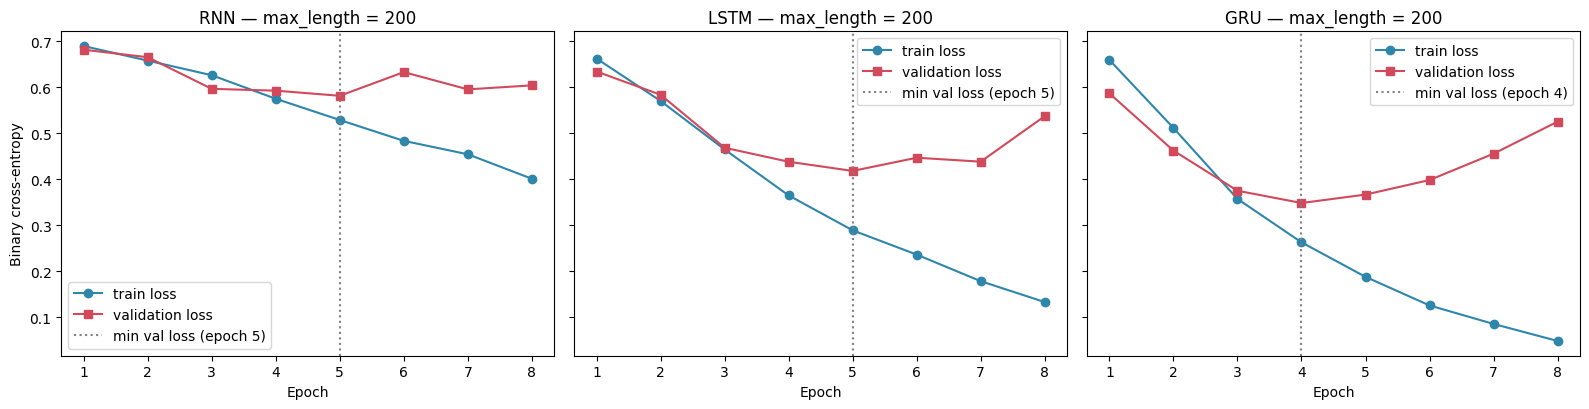

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, arch in zip(axes, ARCHS):
    run = RUNS[(arch, MAX_LEN, "head")]
    h = run["history"]
    ax.plot(h["epoch"], h["train_loss"], "o-", color="#2e86ab", label="train loss")
    ax.plot(h["epoch"], h["val_loss"], "s-", color="#d1495b", label="validation loss")
    ax.axvline(run["row"]["best_epoch"], color="gray", ls=":", label=f"min val loss (epoch {run['row']['best_epoch']})")
    ax.set_title(f"{arch} — max_length = {MAX_LEN}")
    ax.set_xlabel("Epoch")
    ax.set_xticks(h["epoch"])
    ax.legend()
axes[0].set_ylabel("Binary cross-entropy")
plt.tight_layout()
fig.savefig("learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [26]:
pd.concat({arch: RUNS[(arch, MAX_LEN, "head")]["history"].set_index("epoch")[["train_loss", "val_loss", "val_acc"]]
           for arch in ARCHS}, axis=1).round(4)

RNN                        LSTM                         GRU  \
      train_loss val_loss val_acc train_loss val_loss val_acc train_loss   
epoch                                                                      
1         0.6890   0.6811  0.5547     0.6620   0.6338  0.6348     0.6590   
2         0.6575   0.6648  0.5952     0.5699   0.5833  0.6913     0.5113   
3         0.6257   0.5962  0.6998     0.4646   0.4683  0.7893     0.3572   
4         0.5746   0.5922  0.7014     0.3648   0.4379  0.7976     0.2629   
5         0.5285   0.5811  0.7159     0.2889   0.4179  0.8358     0.1879   
6         0.4832   0.6325  0.6630     0.2362   0.4466  0.7982     0.1258   
7         0.4541   0.5950  0.7250     0.1785   0.4381  0.8313     0.0857   
8         0.4009   0.6037  0.7115     0.1331   0.5368  0.8184     0.0487   

                        
      val_loss val_acc  
epoch                   
1       0.5863  0.7062  
2       0.4620  0.7922  
3       0.3749  0.8386  
4       0.3483  0.8505  
5       0.3665  0.8579  
6       0.3981  0.8487  
7       0.4554  0.8513  
8       0.5249  0.8483

Norm của gradient (trước khi clip ở `CLIP = 5`) theo epoch — trung bình và lớn nhất trên các batch:

In [27]:
pd.concat({arch: RUNS[(arch, MAX_LEN, "head")]["history"].set_index("epoch")[["grad_norm_mean", "grad_norm_max"]]
           for arch in ARCHS}, axis=1).round(3)

RNN                         LSTM                \
      grad_norm_mean grad_norm_max grad_norm_mean grad_norm_max   
epoch                                                             
1              0.657         4.586          0.311         3.590   
2              0.898        32.722          0.785         8.664   
3              0.997        31.867          0.886         5.915   
4              1.108        43.310          1.099         8.504   
5              0.997        11.169          1.163        11.479   
6              1.626       115.073          1.108        10.936   
7              1.414        64.724          0.955         6.609   
8              1.213        25.421          0.937         7.089   

                 GRU                
      grad_norm_mean grad_norm_max  
epoch                               
1              0.566         5.064  
2              0.996         5.184  
3              0.984         8.404  
4              0.950         3.704  
5              0.942         2.748  
6              0.878         2.696  
7              0.824         4.069  
8              0.660         2.592

> ✍️ **Tự trả lời:** Kết quả thực nghiệm có phù hợp với prediction ban đầu (Prediction 2, 5) không? Không kết luận chỉ dựa vào accuracy, xét cả số tham số, training time, learning curves.
>
> Prediction 2 (LSTM xử lý dependency dài tốt hơn RNN) phù hợp với kết quả. LSTM có F1 0.823 so với 0.709 của RNN, val loss tốt nhất 0.418 so với 0.581. Learning curve của RNN dao động, còn LSTM giảm đều tới epoch 5. Gradient norm max của RNN có lúc lên 115, của LSTM tối đa 11.5, cho thấy gate giúp gradient ổn định hơn. Cái giá là LSTM có 117,760 tham số recurrent, gấp 4 lần RNN (29,440).
>
> Prediction 5 (LSTM luôn tốt hơn RNN) không phù hợp. LSTM thắng RNN trên IMDb nhưng không phải mô hình tốt nhất: GRU có ít tham số recurrent hơn (88,320), train nhanh hơn (42.5s so với 74.7s) mà F1 vẫn cao hơn (0.829). Lab chỉ thử trên một dataset nên không thể kết luận cho mọi dataset.

> ✍️ **Tự trả lời:** Learning curves: model nào có dấu hiệu overfitting, bắt đầu từ epoch nào? (không chỉ nhìn epoch cuối cùng)
>
> Cả ba model đều có dấu hiệu overfitting: train loss vẫn giảm nhưng val loss bắt đầu tăng.
> - **GRU:** val loss thấp nhất ở epoch 4 (0.348), sau đó tăng liên tục lên 0.525 ở epoch 8, trong khi train loss giảm từ 0.263 xuống 0.049. GRU overfit sớm và rõ nhất, bắt đầu từ epoch 5.
> - **LSTM:** val loss thấp nhất ở epoch 5 (0.418), sau đó dao động rồi tăng lên 0.537 ở epoch 8, train loss xuống còn 0.133. Overfit bắt đầu từ epoch 6.
> - **RNN:** val loss thấp nhất ở epoch 5 (0.581), sau đó lên xuống (0.633, 0.595, 0.604). Train loss vẫn còn 0.401, nên RNN vừa học chưa tốt vừa không ổn định, overfit nhẹ hơn hai model kia.
>
> Nếu chỉ nhìn epoch cuối thì sẽ đánh giá sai cả ba model, vì vậy khi test mình dùng trọng số của epoch có val loss thấp nhất.

## 8. Experiment 2 & 5 — max_length, padding, truncation (Đề §13, §20)

Giữ architecture cố định, chỉ đổi `max_length ∈ {50, 100, 200}` (truncation `head`).
Chạy cho cả ba architecture; **architecture cố định chính là LSTM** (bảng §13).
Thêm `max_length = 30` để kiểm chứng Prediction 4.

In [28]:
SEQ_LENS = [30, *MAX_LENS]
for arch in ARCHS:
    for L in SEQ_LENS:
        get_run(arch, L)

seq_tbl = pd.DataFrame([RUNS[(a, L, "head")]["row"] for a in ARCHS for L in SEQ_LENS])
print(f"Bảng §13 — {FIXED_ARCH}")
(seq_tbl[seq_tbl["model"] == FIXED_ARCH]
 .set_index("max_len")[["pct_tokens_retained", "train_time_s", "accuracy", "f1"]]
 .rename(columns={"pct_tokens_retained": "% tokens retained", "train_time_s": "Training time (s)",
                  "accuracy": "Accuracy", "f1": "F1"}).round(4))

  [RNN L=30 head] epoch 1: train 0.6997 | val 0.6842 | val acc 0.5672 | 1.8s


  [RNN L=30 head] epoch 2: train 0.6805 | val 0.6862 | val acc 0.5579 | 1.7s


  [RNN L=30 head] epoch 3: train 0.6432 | val 0.6645 | val acc 0.5989 | 1.7s


  [RNN L=30 head] epoch 4: train 0.5919 | val 0.6214 | val acc 0.6677 | 1.7s


  [RNN L=30 head] epoch 5: train 0.5384 | val 0.6159 | val acc 0.6820 | 1.9s


...

  [GRU L=100 head] epoch 6: train 0.1489 | val 0.5296 | val acc 0.8115 | 5.6s


  [GRU L=100 head] epoch 7: train 0.0933 | val 0.5688 | val acc 0.8103 | 5.8s


  [GRU L=100 head] epoch 8: train 0.0586 | val 0.6796 | val acc 0.8166 | 6.2s


Bảng §13 — LSTM


,% tokens retained,Training time (s),Accuracy,F1
max_len,,,,
30,12.8580,21.9282,0.7018,0.6877
50,21.3539,33.2001,0.7404,0.7338
100,41.3102,50.0296,0.7675,0.7724
200,68.3678,74.6514,0.8214,0.8233


In [29]:
(seq_tbl.set_index(["model", "max_len"])
 [["pct_tokens_retained", "train_time_s", "time_per_epoch_s", "peak_gpu_mem_mb", "best_epoch",
   "best_val_loss", "accuracy", "f1"]].round(4))

pct_tokens_retained  train_time_s  time_per_epoch_s  \
model max_len                                                        
RNN   30                   12.8580       14.6089            1.8261   
      50                   21.3539       19.5541            2.4443   
      100                  41.3102       25.1922            3.1490   
      200                  68.3678       80.7982           10.0998   
LSTM  30                   12.8580       21.9282            2.7410   
      50                   21.3539       33.2001            4.1500   
      100                  41.3102       50.0296            6.2537   
      200                  68.3678       74.6514            9.3314   
GRU   30                   12.8580       26.8175            3.3522   
      50                   21.3539       36.8822            4.6103   
      100                  41.3102       48.2213            6.0277   
      200                  68.3678       42.5018            5.3127   

               peak_gpu_mem_mb  best_epoch  best_val_loss  accuracy      f1  
model max_len                                                                
RNN   30               66.6924           5         0.6159    0.6633  0.6608  
      50               84.4844           2         0.6734    0.5892  0.5803  
      100             126.9023           4         0.6597    0.6443  0.6616  
      200             210.7524           5         0.5811    0.7099  0.7087  
LSTM  30               92.6240           4         0.5504    0.7018  0.6877  
      50              125.3018           4         0.5062    0.7404  0.7338  
      100             202.7104           5         0.4877    0.7675  0.7724  
      200             318.9937           5         0.4179    0.8214  0.8233  
GRU   30               83.3135           3         0.5476    0.7054  0.7249  
      50              111.0293           4         0.4903    0.7370  0.7420  
      100             176.7744           4         0.4075    0.8016  0.7943  
      200             276.3081           4         0.3483    0.8356  0.8286

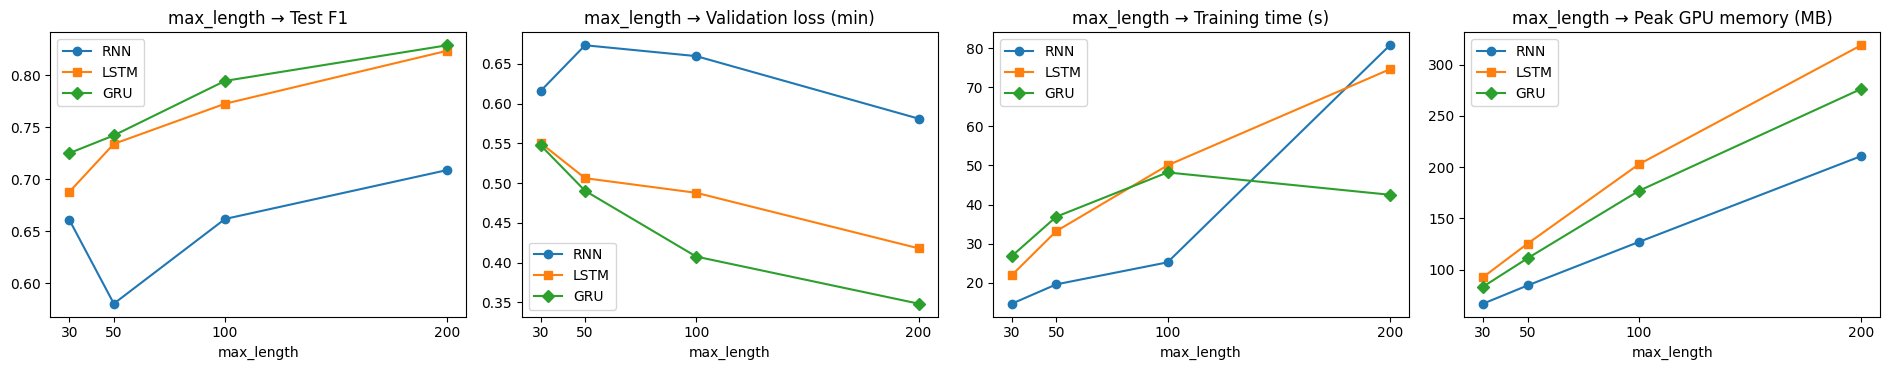

In [30]:
fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))
specs = [("f1", "Test F1"), ("best_val_loss", "Validation loss (min)"),
         ("train_time_s", "Training time (s)"), ("peak_gpu_mem_mb", "Peak GPU memory (MB)")]
for ax, (col, title) in zip(axes, specs):
    for arch, marker in zip(ARCHS, "osD"):
        d = seq_tbl[seq_tbl["model"] == arch]
        ax.plot(d["max_len"], d[col], marker=marker, label=arch)
    ax.set_xticks(SEQ_LENS)
    ax.set_xlabel("max_length")
    ax.set_title(f"max_length → {title}")
    ax.legend()
plt.tight_layout()
fig.savefig("sequence_length.png", dpi=150, bbox_inches="tight")
plt.show()

### Truncation `head` vs `tail` (phần thêm)
`head` giữ phần đầu review (mất phần kết), `tail` giữ phần cuối (mất phần mở đầu). Cùng LSTM, cùng `max_length`.

In [31]:
for L in [50, 100]:
    get_run(FIXED_ARCH, L, "tail")

(pd.DataFrame([RUNS[(FIXED_ARCH, L, t)]["row"] for L in [50, 100] for t in ["head", "tail"]])
 .set_index(["max_len", "truncation"])[["accuracy", "f1", "best_val_loss"]].round(4))

  [LSTM L=50 tail] epoch 1: train 0.6007 | val 0.5069 | val acc 0.7508 | 4.4s


  [LSTM L=50 tail] epoch 2: train 0.4577 | val 0.4524 | val acc 0.7926 | 4.2s


  [LSTM L=50 tail] epoch 3: train 0.3626 | val 0.4338 | val acc 0.8035 | 4.1s


  [LSTM L=50 tail] epoch 4: train 0.2903 | val 0.4222 | val acc 0.8107 | 4.7s


  [LSTM L=50 tail] epoch 5: train 0.2182 | val 0.4744 | val acc 0.8095 | 5.2s


...

  [LSTM L=100 tail] epoch 5: train 0.2070 | val 0.4126 | val acc 0.8452 | 5.7s


  [LSTM L=100 tail] epoch 6: train 0.1561 | val 0.4356 | val acc 0.8436 | 5.4s


  [LSTM L=100 tail] epoch 7: train 0.1170 | val 0.5241 | val acc 0.8400 | 5.5s


  [LSTM L=100 tail] epoch 8: train 0.0884 | val 0.5271 | val acc 0.8289 | 5.9s


accuracy      f1  best_val_loss
max_len truncation                                 
50      head          0.7404  0.7338         0.5062
        tail          0.8010  0.7998         0.4222
100     head          0.7675  0.7724         0.4877
        tail          0.8255  0.8332         0.3918

> ✍️ **Tự trả lời:** Tăng `max_length` có luôn cải thiện performance không? (so sánh giữa RNN và LSTM/GRU)
>
> Không phải luôn luôn. Với LSTM và GRU, tăng max_length từ 30 lên 200 làm F1 tăng đều (LSTM: 0.688, 0.734, 0.772, 0.823; GRU: 0.725, 0.742, 0.794, 0.829) và val loss giảm đều.
>
> Với RNN thì không như vậy: F1 ở max_length 50 (0.580) còn thấp hơn ở 30 (0.661), ở 100 (0.662) cũng chỉ ngang 30, đến 200 mới tăng lên 0.709. Training của RNN ở 50 và 100 dao động mạnh, ở 50 epoch tốt nhất chỉ là epoch 2. RNN không nhớ được thông tin ở xa nên thêm token chưa chắc đã giúp, còn LSTM và GRU có gate nên tận dụng được context dài hơn.

> ✍️ **Tự trả lời:** Nếu `max_length` quá nhỏ, loại thông tin nào có thể bị mất? (dựa vào bảng head vs tail)
>
> Khi max_length nhỏ và cắt kiểu head, model chỉ đọc phần mở đầu review, thường là phần giới thiệu, tóm tắt nội dung, tên diễn viên. Phần kết luận ở cuối, nơi người viết hay đưa ra đánh giá chung ("overall", "I recommend", chấm điểm), sẽ bị mất.
>
> Bảng head vs tail cho thấy rõ điều này. Với LSTM, giữ phần cuối cho F1 0.800 so với 0.734 ở max_length 50, và 0.833 so với 0.772 ở max_length 100. LSTM tail ở max_length 100 còn tốt hơn LSTM head ở max_length 200 (0.823). Vậy với IMDb, thông tin sentiment quan trọng tập trung nhiều ở cuối review.

> ✍️ **Tự trả lời:** Có tồn tại trade-off giữa context và computational cost không? (training time, memory)
>
> Có. Context càng dài thì chi phí càng cao. Với LSTM, đi từ max_length 30 lên 200, thời gian mỗi epoch tăng từ 2.7s lên 9.3s và GPU memory từ 93 MB lên 319 MB, đổi lại F1 tăng từ 0.688 lên 0.823. RNN cũng tương tự: 1.8s lên 10.1s, 67 MB lên 211 MB.
>
> Lý do là recurrent model phải tính tuần tự từng timestep và lưu hidden state của mọi bước để backprop, nên thời gian và memory tăng gần tuyến tính theo độ dài. Trong khi đó lợi ích thì giảm dần, vì những token thêm vào ở xa thường ít được model dùng tới (RNN gần như bỏ qua phần đầu). GRU ở max_length 200 lại chạy nhanh hơn ở 100, có thể do dao động khi đo thời gian trên GPU, không phải quy luật chung.

## 9. Experiment 6 — Long-range dependency (Đề §21)

### 9.1 Câu ví dụ trong đề
Từ quyết định sentiment đặt ở đầu / giữa / cuối câu.

In [32]:
EXAMPLES = {
    ("end", "positive"): "The movie was, despite many unnecessary scenes, ultimately excellent.",
    ("end", "negative"): "The movie was, despite many unnecessary scenes, ultimately terrible.",
    ("middle", "positive"): "The movie was ultimately excellent, despite many unnecessary scenes.",
    ("middle", "negative"): "The movie was ultimately terrible, despite many unnecessary scenes.",
    ("beginning", "positive"): "Excellent movie, ultimately, despite many unnecessary scenes.",
    ("beginning", "negative"): "Terrible movie, ultimately, despite many unnecessary scenes.",
}
MODELS_ALL = {"TF-IDF + LR": RUN_TFIDF, **{a: RUNS[(a, MAX_LEN, "head")] for a in ARCHS}}
ex = pd.DataFrame({"position": [k[0] for k in EXAMPLES], "true": [k[1] for k in EXAMPLES],
                   "sentence": list(EXAMPLES.values())})
for name, run in MODELS_ALL.items():
    ex[f"P(pos) {name}"] = proba_texts(run, ex["sentence"].tolist())
ex.round(4)

,position,true,sentence,P(pos) TF-IDF + LR,P(pos) RNN,P(pos) LSTM,P(pos) GRU
0,end,positive,"The movie was, despite many unnecessary scenes, ultimately excellent.",0.8800,0.7959,0.8139,0.8659
1,end,negative,"The movie was, despite many unnecessary scenes, ultimately terrible.",0.0084,0.1683,0.0930,0.3123
2,middle,positive,"The movie was ultimately excellent, despite many unnecessary scenes.",0.8800,0.7010,0.8601,0.8725
3,middle,negative,"The movie was ultimately terrible, despite many unnecessary scenes.",0.0084,0.2836,0.0733,0.0997
4,beginning,positive,"Excellent movie, ultimately, despite many unnecessary scenes.",0.9002,0.8303,0.9405,0.9236
5,beginning,negative,"Terrible movie, ultimately, despite many unnecessary scenes.",0.0093,0.3184,0.0918,0.0908


### 9.2 Thí nghiệm có kiểm soát: vị trí × khoảng cách

Một câu quyết định sentiment (3 cặp positive/negative) được chèn vào **đầu / giữa / cuối** một đoạn filler
mô tả nội dung phim gồm `k` câu (chèn theo ranh giới câu). Các câu filler được chọn sao cho TF-IDF + LR đánh giá
gần trung tính (P(pos) ≈ 0.5); bảng đầu tiên kiểm tra mức trung tính của filler với **từng** model.
Đo:
- `gap` = P(pos | câu positive) − P(pos | câu negative), trung bình trên 3 cặp (1 = tách hoàn hảo, 0 = không phân biệt);
- `acc` = tỉ lệ dự đoán đúng trên 6 câu.

Tổng độ dài < 200 token nên không có truncation.

In [33]:
FILLER_SENTS = [
    "the director also produced the film and appears in a small role",
    "the film was shot over two months and runs for about two hours",
    "the second half of the movie takes place in a hotel",
    "in one scene the characters discuss the weather and the traffic",
    "she meets a man at the airport and they talk about their jobs",
    "the budget was small and the movie was released in a few theaters",
    "the opening scene shows a car driving through the desert",
    "there is a subplot about a missing dog and a neighbor",
    "the movie is based on a novel that was published in the seventies",
    "the dialogue is mostly in english with some scenes in spanish",
]
KEY_PAIRS = [("overall the movie was excellent", "overall the movie was terrible"),
             ("i really loved this film", "i really hated this film"),
             ("it was a wonderful experience", "it was an awful experience")]
N_SENTS = [1, 3, 6, 10, 15]
POSITIONS = ["beginning", "middle", "end"]


def filler(k):
    return [FILLER_SENTS[i % len(FILLER_SENTS)] for i in range(k)]


def build(key, k, position):
    sents = filler(k)
    sents.insert({"beginning": 0, "middle": k // 2, "end": k}[position], key)
    return " . ".join(sents) + " ."


FILLER_TOKENS = {k: len(pp.tokenize(" . ".join(filler(k)))) for k in N_SENTS}
print("P(pos) của riêng filler (không có câu quyết định):")
display(pd.DataFrame({name: proba_texts(run, [" . ".join(filler(k)) for k in N_SENTS]) for name, run in MODELS_ALL.items()},
                     index=pd.Index([FILLER_TOKENS[k] for k in N_SENTS], name="filler_len (token)")).round(3))
print("Ví dụ (k=3, middle):", build(KEY_PAIRS[0][0], 3, "middle"))

rows = []
for k in N_SENTS:
    for position in POSITIONS:
        texts = [build(key, k, position) for pair in KEY_PAIRS for key in pair]
        y = np.array([1, 0] * len(KEY_PAIRS))
        for name, run in MODELS_ALL.items():
            p = proba_texts(run, texts)
            rows.append({"filler_len": FILLER_TOKENS[k], "position": position, "model": name,
                         "gap": p[y == 1].mean() - p[y == 0].mean(), "acc": ((p >= 0.5) == y).mean()})
long_range = pd.DataFrame(rows)
long_range.pivot_table(index=["filler_len", "position"], columns="model", values="gap")[list(MODELS_ALL)].round(3)

P(pos) của riêng filler (không có câu quyết định):


,TF-IDF + LR,RNN,LSTM,GRU
filler_len (token),,,,
12,0.482,0.343,0.591,0.606
36,0.527,0.170,0.916,0.867
73,0.624,0.347,0.955,0.873
118,0.458,0.230,0.868,0.675
178,0.493,0.522,0.959,0.864


Ví dụ (k=3, middle): the director also produced the film and appears in a small role . overall the movie was excellent . the film was shot over two months and runs for about two hours . the second half of the movie takes place in a hotel .


model                 TF-IDF + LR    RNN   LSTM    GRU
filler_len position                                   
12         beginning        0.858  0.538  0.537  0.538
           end              0.858  0.357  0.662  0.575
           middle           0.858  0.538  0.537  0.538
36         beginning        0.648  0.557  0.480  0.359
           end              0.648  0.308  0.439  0.463
           middle           0.648  0.184  0.468  0.321
73         beginning        0.432  0.064  0.581  0.335
           end              0.432  0.381  0.325  0.335
           middle           0.432  0.012  0.331  0.361
118        beginning        0.354  0.000  0.467  0.287
           end              0.354  0.278  0.489  0.594
           middle           0.354  0.000  0.400  0.218
178        beginning        0.237  0.000  0.558  0.101
           end              0.237  0.492  0.308  0.455
           middle           0.237  0.000  0.014  0.114

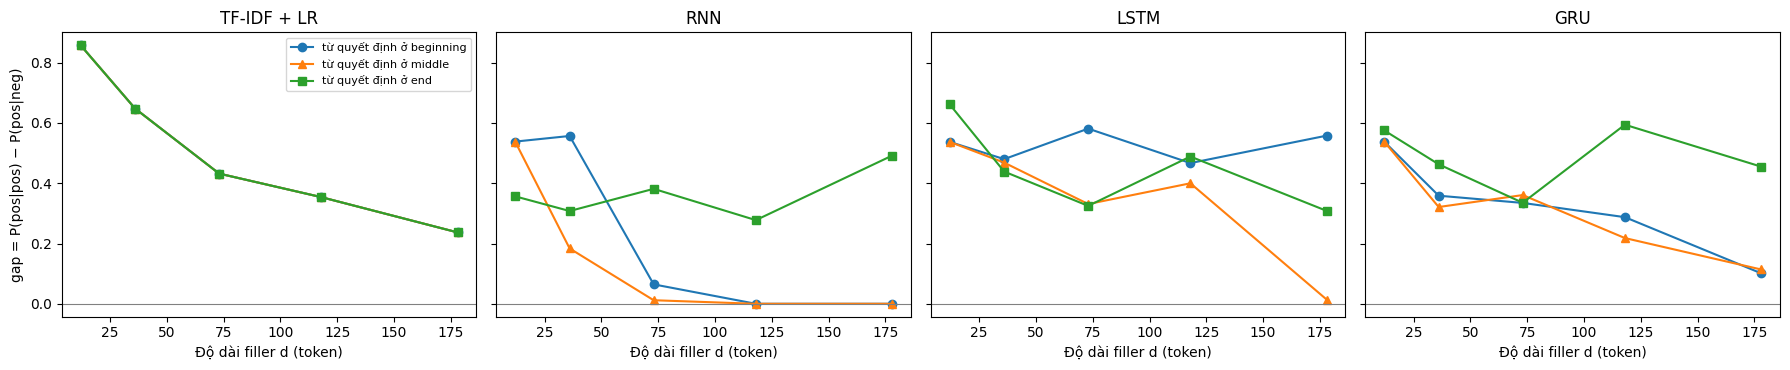

model                 TF-IDF + LR   RNN  LSTM   GRU
filler_len position                                
12         beginning          1.0  1.00  1.00  0.83
           end                1.0  0.67  1.00  0.83
           middle             1.0  1.00  1.00  0.83
36         beginning          1.0  1.00  0.83  0.67
           end                1.0  0.67  0.83  0.83
           middle             1.0  0.67  0.83  0.67
73         beginning          1.0  0.50  0.83  0.67
           end                1.0  0.67  0.50  0.50
           middle             1.0  0.50  0.67  0.67
118        beginning          1.0  0.50  0.83  0.83
           end                1.0  0.67  0.83  1.00
           middle             1.0  0.50  0.83  0.67
178        beginning          1.0  0.50  0.83  0.50
           end                1.0  1.00  0.50  0.83
           middle             1.0  0.50  0.50  0.50

In [34]:
fig, axes = plt.subplots(1, len(MODELS_ALL), figsize=(18, 3.8), sharey=True)
for ax, name in zip(axes, MODELS_ALL):
    for position, marker in zip(POSITIONS, "o^s"):
        d = long_range[(long_range["model"] == name) & (long_range["position"] == position)]
        ax.plot(d["filler_len"], d["gap"], marker=marker, label=f"từ quyết định ở {position}")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_title(name)
    ax.set_xlabel("Độ dài filler d (token)")
axes[0].set_ylabel("gap = P(pos|pos) − P(pos|neg)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
long_range.pivot_table(index=["filler_len", "position"], columns="model", values="acc")[list(MODELS_ALL)].round(2)

### 9.3 Mỗi vị trí ảnh hưởng tới prediction bao nhiêu? (phần thêm)

Trên 1,000 review test có ≥ 200 token (không padding), tính $\|\partial z / \partial e_t\|_2$ — độ nhạy của logit
$z$ theo embedding của token ở vị trí $t$ — rồi lấy trung bình. Đây là quan sát thực nghiệm về model đã train,
không phải chứng minh vanishing gradient.

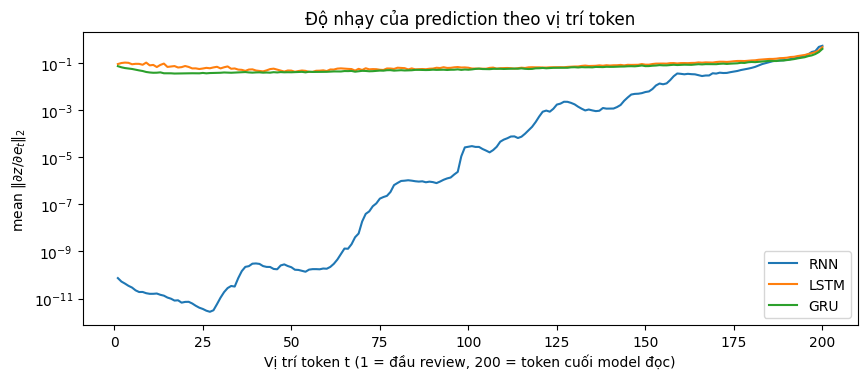

,% tổng độ nhạy ở 50 token đầu,% ở 100 token giữa,% ở 50 token cuối,token cuối / token đầu
RNN,8.729131e-08,1.324878,98.675110,7.230687e+09
LSTM,1.985612e+01,37.122578,43.021305,5.242505e+00
GRU,1.534975e+01,40.577503,44.072750,5.402524e+00


In [35]:
def position_saliency(run, n_reviews=1000, batch_size=100):
    ids, lengths = get_data(MAX_LEN)["test"]
    idx = np.flatnonzero(lengths == MAX_LEN)[:n_reviews]
    model = run["model"].eval()
    sal = []
    with torch.backends.cudnn.flags(enabled=False):   # cuDNN RNN không backward được ở eval mode
        for i in range(0, len(idx), batch_size):
            b = idx[i:i + batch_size]
            emb = model.embedding(torch.as_tensor(ids[b], device=DEVICE)).detach().requires_grad_(True)
            model.from_embeddings(emb, torch.as_tensor(lengths[b])).sum().backward()
            sal.append(emb.grad.norm(dim=-1).cpu().numpy())
    return np.concatenate(sal).mean(axis=0)


saliency = {a: position_saliency(RUNS[(a, MAX_LEN, "head")]) for a in ARCHS}
fig, ax = plt.subplots(figsize=(10, 3.8))
for a in ARCHS:
    ax.semilogy(np.arange(1, MAX_LEN + 1), saliency[a], label=a)
ax.set_xlabel("Vị trí token t (1 = đầu review, 200 = token cuối model đọc)")
ax.set_ylabel(r"mean $\|\partial z / \partial e_t\|_2$")
ax.set_title("Độ nhạy của prediction theo vị trí token")
ax.legend()
plt.show()

pd.DataFrame({a: {"% tổng độ nhạy ở 50 token đầu": 100 * s[:50].sum() / s.sum(),
                  "% ở 100 token giữa": 100 * s[50:150].sum() / s.sum(),
                  "% ở 50 token cuối": 100 * s[150:].sum() / s.sum(),
                  "token cuối / token đầu": s[-1] / s[0]} for a, s in saliency.items()}).T

> ✍️ **Tự trả lời:** Vị trí của thông tin quan trọng ảnh hưởng thế nào tới prediction của từng model? Phân biệt rõ **empirical observation** (bảng/hình ở trên) với **theoretical explanation** (vanishing gradient, gates), thí nghiệm nhỏ này không chứng minh đầy đủ vanishing gradient.
>
> **Empirical observation:**
> - Với các câu ví dụ của đề (9.1), câu ngắn nên cả 4 model đều đoán đúng ở mọi vị trí.
> - Trong thí nghiệm filler (9.2), gap của TF-IDF giống nhau ở cả ba vị trí vì nó không quan tâm thứ tự, nhưng giảm khi filler dài ra (0.858 xuống 0.237) do câu quyết định bị pha loãng giữa nhiều từ khác.
> - RNN quên hẳn câu quyết định đặt ở đầu hoặc giữa khi filler từ 118 token trở lên (gap = 0.000), nhưng vẫn phân biệt được khi câu đó nằm ở cuối (0.278 và 0.492).
> - LSTM và GRU không theo quy luật rõ ràng. Ở 178 token filler, LSTM vẫn giữ gap 0.558 khi câu ở đầu nhưng ở giữa gần như bằng 0 (0.014). GRU giữ tốt nhất khi câu ở cuối, còn ở đầu và giữa gap giảm xuống khoảng 0.1.
> - Độ nhạy theo vị trí (9.3): RNN dồn 98.7% vào 50 token cuối và gần như 0% ở 50 token đầu. LSTM và GRU phân bố đều hơn: khoảng 15 đến 20% ở 50 token đầu và 43 đến 44% ở 50 token cuối.
>
> **Theoretical explanation:** với RNN, thông tin từ token ở xa phải đi qua tích của nhiều Jacobian nên gradient tắt dần, model không học được cách dùng các token đầu (vanishing gradient, mục 4.4). LSTM có cell state được cập nhật bằng phép cộng $c_t = f_t c_{t-1} + i_t \tilde{c}_t$, khi forget gate gần 1 thì thông tin và gradient đi qua nhiều bước mà ít bị suy giảm. GRU có update gate với vai trò tương tự.
>
> Tuy vậy thí nghiệm này chỉ có 3 cặp câu, và kết quả còn phụ thuộc vào filler (LSTM và GRU coi filler là khá positive, P(pos) từ 0.6 đến 0.96), nên đây chỉ là quan sát gợi ý, chưa chứng minh được vanishing gradient.

## 10. Evaluation & Confusion matrix (Đề §22)

Positive class = `positive` (label 1). Bố cục: hàng = Actual (Pos, Neg), cột = Predicted (Pos, Neg)
→ `[[TP, FN], [FP, TN]]`. Hình được lưu vào `confusion_matrix.png`.

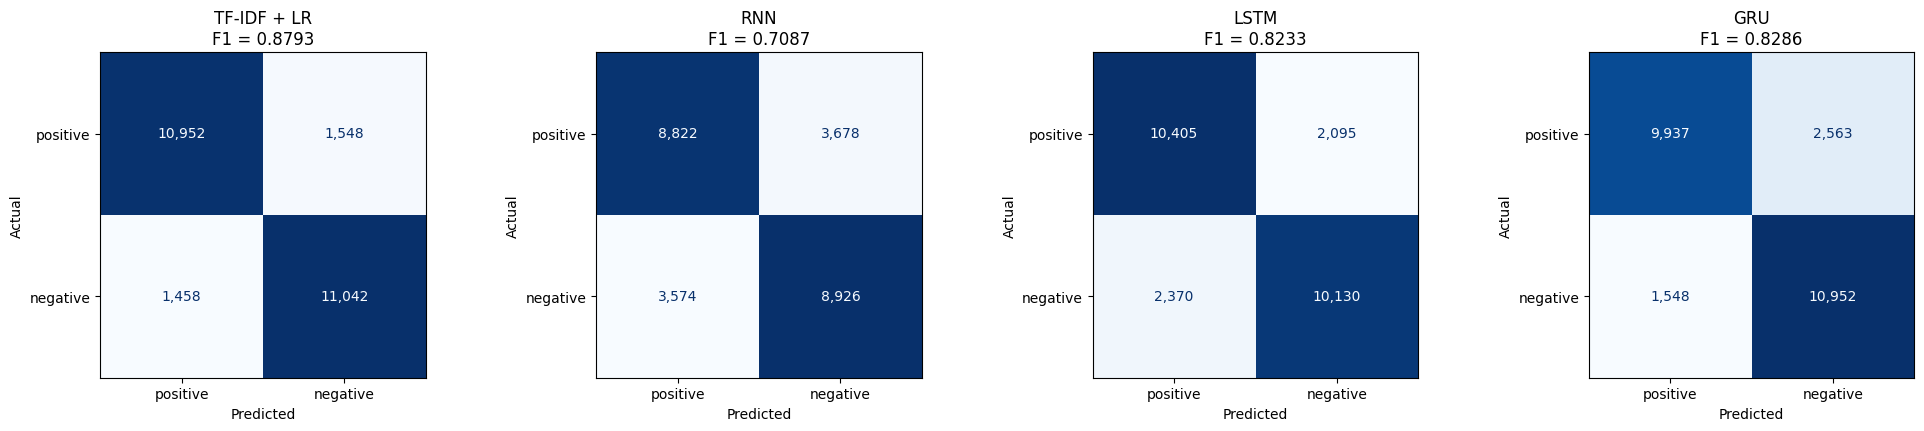

In [36]:
fig, axes = plt.subplots(1, len(MODELS_ALL), figsize=(5 * len(MODELS_ALL), 4.4))
for ax, (name, run) in zip(axes, MODELS_ALL.items()):
    cm = confusion_matrix(y_test, run["y_pred"], labels=[1, 0])
    ConfusionMatrixDisplay(cm, display_labels=["positive", "negative"]).plot(
        ax=ax, cmap="Blues", values_format=",d", colorbar=False)
    ax.set_title(f"{name}\nF1 = {run['row']['f1']:.4f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
fig.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [37]:
rows = []
for name, run in MODELS_ALL.items():
    tn, fp, fn, tp = confusion_matrix(y_test, run["y_pred"], labels=[0, 1]).ravel()
    r = run["row"]
    rows.append({"model": name, "TP": tp, "FN": fn, "FP": fp, "TN": tn,
                 "accuracy": r["accuracy"], "precision": r["precision"], "recall": r["recall"], "f1": r["f1"],
                 "n_params": r["n_params"], "train_time_s": r["train_time_s"], "epochs": r["epochs"],
                 "best_epoch": r["best_epoch"], "max_len": r["max_len"], "vocab_size": r["vocab_size"]})
pd.DataFrame(rows).set_index("model").round(4)

,TP,FN,FP,TN,accuracy,precision,recall,f1,n_params,train_time_s,epochs,best_epoch,max_len,vocab_size
model,,,,,,,,,,,,,,
TF-IDF + LR,10952,1548,1458,11042,0.8798,0.8825,0.8762,0.8793,43078,5.8637,NaN,NaN,full,43077
RNN,8822,3678,3574,8926,0.7099,0.7117,0.7058,0.7087,2029769,80.7982,8.0,5.0,200,20002
LSTM,10405,2095,2370,10130,0.8214,0.8145,0.8324,0.8233,2118089,74.6514,8.0,5.0,200,20002
GRU,9937,2563,1548,10952,0.8356,0.8652,0.7950,0.8286,2088649,42.5018,8.0,4.0,200,20002


> ✍️ **Tự trả lời:** Ngoài accuracy/F1: so sánh các model theo số tham số, training time, sequence length, vocabulary size. Loại lỗi nào (FP hay FN) chiếm nhiều hơn ở từng model?
>
> **Số tham số:** TF-IDF + LR chỉ có 43,078 tham số, còn RNN, LSTM, GRU có khoảng 2.03 đến 2.12 triệu, phần lớn nằm ở embedding (20,002 × 100 = 2 triệu). Phần recurrent chỉ có 29k (RNN), 88k (GRU), 118k (LSTM).
>
> **Training time:** TF-IDF 5.9s, GRU 42.5s, LSTM 74.7s, RNN 80.8s.
>
> **Sequence length:** TF-IDF đọc toàn bộ review, còn các sequence model chỉ đọc 200 token đầu (68.4% số token của test).
>
> **Vocabulary size:** TF-IDF dùng 43,077 từ, sequence model chỉ dùng 20,002 nên 3.3% token của test bị thành `<unk>`. Hai điểm này là bất lợi của sequence model và giải thích một phần vì sao TF-IDF vẫn tốt nhất.
>
> **Loại lỗi:**
> - TF-IDF khá cân bằng: 1,548 FN và 1,458 FP.
> - RNN cũng gần cân bằng: 3,678 FN và 3,574 FP, nhưng số lỗi gấp đôi.
> - LSTM có FP nhiều hơn (2,370 so với 2,095 FN), hơi nghiêng về đoán positive.
> - GRU có FN nhiều hơn hẳn (2,563 so với 1,548 FP), nghiêng về đoán negative, nên precision cao (0.865) nhưng recall thấp (0.795).

## 11. Error analysis (Đề §24)

Model phân tích: model tốt nhất (theo F1 trên **validation**) trong RNN / LSTM / GRU với `max_length = 200`.
Chọn ngẫu nhiên (seed cố định) **3 correctly** + **3 incorrectly classified** từ test.

Mỗi review in kèm: P(pos) của model, P(pos) của TF-IDF + LR (để xem lỗi có riêng của sequence model không),
phần bị truncation cắt mất, và các token ảnh hưởng nhiều nhất theo **occlusion** — xóa từng token và đo
P(pos) thay đổi bao nhiêu (`+` = token đẩy về positive, `−` = đẩy về negative), kèm context xung quanh.
Việc xác định nguyên nhân lỗi ghi vào `error_analysis.md`.

In [38]:
best_arch = max(ARCHS, key=lambda a: RUNS[(a, MAX_LEN, "head")]["row"]["val_f1"])
run_best = RUNS[(best_arch, MAX_LEN, "head")]
print(f"Model phân tích: {best_arch} (val F1 = {run_best['row']['val_f1']:.4f})")

correct = np.flatnonzero(run_best["y_pred"] == y_test)
wrong = np.flatnonzero(run_best["y_pred"] != y_test)
print(f"Correct: {len(correct):,} | Incorrect: {len(wrong):,}")

rng = np.random.default_rng(SEED)
sample_correct = rng.choice(correct, 3, replace=False)
sample_wrong = rng.choice(wrong, 3, replace=False)


@torch.no_grad()
def occlusion(run, tokens):
    # Xóa lần lượt từng token trong phần model đọc; delta = P(pos) gốc - P(pos) khi thiếu token đó
    ids = vocab.encode(tokens)[:run["row"]["max_len"]] or [pp.UNK]
    n = len(ids)
    arr = np.zeros((n + 1, n), dtype=np.int64)
    arr[0] = ids
    for i in range(n):
        v = ids[:i] + ids[i + 1:]
        arr[i + 1, :len(v)] = v
    lens = np.array([n] + [max(n - 1, 1)] * n)
    p = sigmoid(predict_logits(run["model"], arr, lens))
    df = pd.DataFrame({"pos": range(n), "token": tokens[:n], "delta": p[0] - p[1:]})
    df["context"] = [" ".join(tokens[max(0, i - 3):i] + [f"[{tokens[i]}]"] + tokens[i + 1:i + 4]) for i in range(n)]
    return p[0], df


def show_example(i, run=run_best, max_chars=1500, top=6):
    toks, L = test_df.at[i, "tokens"], run["row"]["max_len"]
    p, occ = occlusion(run, toks)
    print("=" * 110)
    print(f"test idx={i} | true={pp.LABEL_NAMES[y_test[i]]} | pred {run['row']['model']}="
          f"{pp.LABEL_NAMES[run['y_pred'][i]]} (P(pos)={p:.3f}) | TF-IDF+LR P(pos)={proba_tfidf[i]:.3f}")
    print(f"n_tokens={len(toks)} | " + (f"BỊ CẮT: model chỉ đọc {L} token đầu, mất {len(toks) - L} token cuối"
                                        if len(toks) > L else "không bị cắt"))
    print("-" * 110)
    text = test_df.at[i, "norm"]
    print(text[:max_chars] + (" ..." if len(text) > max_chars else ""))
    if len(toks) > L:
        print("-" * 110)
        print(f"Phần model KHÔNG đọc (từ token {L + 1}):", " ".join(toks[L:])[:600])
    print("-" * 110)
    for title, part in [("Đẩy về positive", occ.nlargest(top, "delta")), ("Đẩy về negative", occ.nsmallest(top, "delta"))]:
        print(title + ":")
        for _, r in part.iterrows():
            print(f"   {r['delta']:+.3f}  @{r['pos']:<3d} {r['context']}")

Model phân tích: GRU (val F1 = 0.8463)
Correct: 20,889 | Incorrect: 4,111


In [39]:
print("##### 3 CORRECTLY CLASSIFIED #####")
for i in sample_correct:
    show_example(i)

##### 3 CORRECTLY CLASSIFIED #####
test idx=15920 | true=positive | pred GRU=positive (P(pos)=0.793) | TF-IDF+LR P(pos)=0.961
n_tokens=163 | không bị cắt
--------------------------------------------------------------------------------------------------------------
overall, the dad's army movie is very funny, although the humour isn't quite as catchy and sparkly as in the tv and radio series. so where does this leave us, the viewers? if you've never seen dad's army then the movie is a good way of bringing yourself up to speed and getting hooked on the mad world of walmington o/s. the downside is that you might not "get it" because, as i said, the humour in the movie is a bit on the stolid side. for dad's army buffs the movie holds nothing new as the story is more or less a cutup of the tv series, but it's a unique chance of seeing your favourites in "high def" as compared to the shitty quality of the bbc video recordings. the movie also features what must be the lamest holdup sequence i

In [40]:
print("##### 3 INCORRECTLY CLASSIFIED #####")
for i in sample_wrong:
    show_example(i)

##### 3 INCORRECTLY CLASSIFIED #####
test idx=2840 | true=negative | pred GRU=positive (P(pos)=0.914) | TF-IDF+LR P(pos)=0.748
n_tokens=286 | BỊ CẮT: model chỉ đọc 200 token đầu, mất 86 token cuối
--------------------------------------------------------------------------------------------------------------
while this isn't an all time classic comedy it is a pretty good little movie to watch if you catch it on a rainy saturday morning with not a lot else going on right then. harold lloyd plays ezekiel cobb, an american coming home after growing up in china where his dad was a missionary.he has come home from china to find an american wife and plans to return to china to continue his father's work.cobb unwittingly is recruited to run for mayor of his corrupt home town when the existing political machine that controls the town realizes that he would make a perfect patsy to run against the current mayor who also is the head of the town's underworld.they figure the bumbling ,stumbling cobb 

### Hỗ trợ phân tích: lỗi phân bố theo độ dài review và so với TF-IDF

In [41]:
err_seq = pd.Series(run_best["y_pred"] != y_test)
err_tfidf = pd.Series(pred_tfidf != y_test)
bucket = pd.cut(test_df["n_tokens"], [0, 100, 200, 400, np.inf], labels=["≤100", "101–200", "201–400", ">400"])
display(pd.DataFrame({"số review": bucket.value_counts().sort_index(),
                      f"error rate {best_arch} (%)": 100 * err_seq.groupby(bucket, observed=False).mean(),
                      "error rate TF-IDF + LR (%)": 100 * err_tfidf.groupby(bucket, observed=False).mean()}).round(2))
pd.Series({"cả hai đúng": (~err_seq & ~err_tfidf).sum(),
           f"{best_arch} đúng, TF-IDF sai": (~err_seq & err_tfidf).sum(),
           f"{best_arch} sai, TF-IDF đúng": (err_seq & ~err_tfidf).sum(),
           "cả hai sai": (err_seq & err_tfidf).sum()}).to_frame("số review")

,số review,error rate GRU (%),error rate TF-IDF + LR (%)
n_tokens,,,
≤100,3163,12.74,11.16
101–200,11761,12.44,11.73
201–400,6971,20.01,12.32
>400,3105,27.38,13.37


,số review
cả hai đúng,19702
"GRU đúng, TF-IDF sai",1187
"GRU sai, TF-IDF đúng",2292
cả hai sai,1819


Các lỗi model **tự tin** nhất và các lỗi trên review **ngắn** nhất (dễ đọc) — có thể dùng `show_example(idx)` để xem chi tiết:

In [42]:
err = pd.DataFrame({"idx": wrong, "true": [pp.LABEL_NAMES[v] for v in y_test[wrong]],
                    "P(pos)": run_best["proba"][wrong], "P(pos) TF-IDF": proba_tfidf[wrong],
                    "n_tokens": test_df.loc[wrong, "n_tokens"].to_numpy(),
                    "text": [t[:150] for t in test_df.loc[wrong, "norm"]]})
err["confidence"] = (err["P(pos)"] - 0.5).abs()
display(err.nlargest(5, "confidence").round(3))
err.nsmallest(5, "n_tokens").round(3)

,idx,true,P(pos),P(pos) TF-IDF,n_tokens,text,confidence
1494,12061,negative,0.997,0.999,81,this movie was pure genius. john waters is brilliant. it is hilarious and i am not sick of it even after seeing it a...,0.497
3714,23038,positive,0.007,0.020,354,"haggard: the movie is the real life story of ryan dunn, and his girlfriend who cheated on him, also with the help fr...",0.493
3123,20284,positive,0.007,0.067,222,"one of the most macabre, depressing, yet eye-opening docs. i've watched in awhile. there's no narration or story tha...",0.493
3879,23867,positive,0.009,0.104,398,"i want to preface this review by saying that i have no idea what ""begotten"" is truly about. all i really know is tha...",0.491
1093,8782,negative,0.991,0.988,139,"yes,the movie is not a piece of art but the first time i watched it i was 10 years old,my parents were out and i sta...",0.491


,idx,true,P(pos),P(pos) TF-IDF,n_tokens,text,confidence
1068,8658,negative,0.661,0.931,8,"more suspenseful, more subtle, much, much more disturbing....",0.161
47,318,negative,0.558,0.152,10,i hope this group of film-makers never re-unites.,0.058
1871,14030,positive,0.215,0.468,22,"subject matter: cosmology, quantum physics and stephen hawking soundtrack: phillip glass have i died and gone to hea...",0.285
336,2665,negative,0.688,0.038,25,"i caught this film late at night on hbo. talk about wooden acting, unbelievable plot, et al. very little going in it...",0.188
237,1761,negative,0.632,0.616,28,"a real hoot, unintentionally. sidney portier's character is so sweet and lovable you want to smack him. nothing abou...",0.132


Ví dụ trong đề §24:

In [43]:
s = "I expected the movie to be bad, but it was actually wonderful."
print(s)
for name, run in MODELS_ALL.items():
    print(f"   {name:12s} P(pos) = {proba_texts(run, [s])[0]:.4f}")
_, occ = occlusion(run_best, pp.tokenize(s))
occ.sort_values("delta", key=abs, ascending=False).round(4).head(8)

I expected the movie to be bad, but it was actually wonderful.
   TF-IDF + LR  P(pos) = 0.6880
   RNN          P(pos) = 0.2589
   LSTM         P(pos) = 0.4766
   GRU          P(pos) = 0.6743


,pos,token,delta,context
11,11,wonderful,0.4256,it was actually [wonderful]
6,6,bad,-0.1858,movie to be [bad] but it was
4,4,to,0.0789,expected the movie [to] be bad but
0,0,i,0.0532,[i] expected the movie
7,7,but,0.0362,to be bad [but] it was actually
2,2,the,0.0254,i expected [the] movie to be
10,10,actually,-0.0223,but it was [actually] wonderful
3,3,movie,-0.0148,i expected the [movie] to be bad


In [44]:
# Bảng khung để copy sang error_analysis.md (cột Analysis tự điền)
print("| # | Text (rút gọn) | True | Predicted | P(pos) | n_tokens | Analysis |")
print("|---|---|---|---|---|---|---|")
for i in [*sample_correct, *sample_wrong]:
    snippet = test_df.at[i, "norm"][:120].replace("|", "/")
    print(f"| {i} | {snippet}... | {pp.LABEL_NAMES[y_test[i]]} | {pp.LABEL_NAMES[run_best['y_pred'][i]]} "
          f"| {run_best['proba'][i]:.3f} | {test_df.at[i, 'n_tokens']} | |")

| # | Text (rút gọn) | True | Predicted | P(pos) | n_tokens | Analysis |
|---|---|---|---|---|---|---|
| 15920 | overall, the dad's army movie is very funny, although the humour isn't quite as catchy and sparkly as in the tv and radi... | positive | positive | 0.793 | 163 | |
| 2129 | not to be mistaken as the highly touted samuel l. jackson vehicle snakes on a plane; snakes on a train is low budget, fe... | negative | negative | 0.198 | 164 | |
| 19021 | key west, for too short a time was "appointment tv" for my family. i'd stop by red lobster and pick up a party tray for ... | positive | positive | 0.872 | 133 | |
| 2840 | while this isn't an all time classic comedy it is a pretty good little movie to watch if you catch it on a rainy saturda... | negative | positive | 0.914 | 286 | |
| 19078 | dogtown and z-boys summary: dogtown and z-boys is a documentary about a group of revolutionary teenagers that changed th... | positive | negative | 0.136 | 844 | |
| 22095 | it's fun to watch a

## 12. So sánh với LAB 04 (Đề §25)

Cùng test set (IMDb test chuẩn, 25,000 review). Kết quả Average Word2Vec + LR lấy từ `../LAB_04/results.csv`.

In [45]:
try:
    lab04 = pd.read_csv("../LAB_04/results.csv")
    w2v = lab04[lab04["representation"] == "Avg Word2Vec"].iloc[0]
    w2v_row = {"model": "Avg Word2Vec + LR (LAB 04)", "accuracy": w2v["accuracy"], "f1": w2v["f1"],
               "train_time_s": w2v["train_time_s"], "n_params / dims": int(w2v["n_dims"]) + 1}
except (FileNotFoundError, IndexError):
    w2v_row = {"model": "Avg Word2Vec + LR (LAB 04)"}

rows = [{"model": "TF-IDF + LR", "accuracy": RUN_TFIDF["row"]["accuracy"], "f1": RUN_TFIDF["row"]["f1"],
         "train_time_s": RUN_TFIDF["row"]["train_time_s"], "n_params / dims": RUN_TFIDF["row"]["n_params"]},
        w2v_row]
for a in ARCHS:
    r = RUNS[(a, MAX_LEN, "head")]["row"]
    rows.append({"model": f"{a} (L={MAX_LEN})", "accuracy": r["accuracy"], "f1": r["f1"],
                 "train_time_s": r["train_time_s"], "n_params / dims": r["n_params"]})
pd.DataFrame(rows).set_index("model").round(4)

,accuracy,f1,train_time_s,n_params / dims
model,,,,
TF-IDF + LR,0.8798,0.8793,5.8637,43078
Avg Word2Vec + LR (LAB 04),0.8582,0.8574,49.0902,101
RNN (L=200),0.7099,0.7087,80.7982,2029769
LSTM (L=200),0.8214,0.8233,74.6514,2118089
GRU (L=200),0.8356,0.8286,42.5018,2088649


| Property | TF-IDF + LR | Avg Word2Vec + LR | RNN | LSTM | GRU |
|---|---|---|---|---|---|
| Sparse representation | v | | | | |
| Dense representation | | v | v | v | v |
| Word order | Limited | x | v | v | v |
| Context-dependent state | x | x | v | v | v |
| Long dependency | x | x | Limited | Improved | Improved |
| Computational cost | Low | Low | Higher | Higher | Higher |
| One vector per word | | v | Embedding | Embedding | Embedding |

> ✍️ **Tự trả lời:** RNN/LSTM/GRU giải quyết được vấn đề gì mà Average Word2Vec không giải quyết tốt?
>
> Average Word2Vec lấy trung bình embedding nên mất hoàn toàn thứ tự từ: "dog bites man" và "man bites dog" cho cùng một vector (mục 4.3), "not good" hay "good not" cũng như nhau. RNN, LSTM, GRU đọc từng token theo thứ tự và cập nhật hidden state, nên cùng một từ có thể được hiểu khác nhau tùy vào context phía trước, ví dụ "like" đứng sau "did not".
>
> Ngoài ra, embedding được học cùng với bài toán sentiment nên các từ như "great", "awful" được đặt ở vị trí có ích cho việc phân loại. Lấy trung bình cũng làm loãng tín hiệu khi review dài và có nhiều từ trung tính, còn sequence model có thể học cách giữ lại phần quan trọng.
>
> Tuy vậy, trên test set, LSTM (0.823) và GRU (0.829) vẫn chưa vượt được Average Word2Vec + LR (F1 0.857). Một phần là do bị cắt ở 200 token và embedding phải học từ đầu với lượng data không lớn.

> ✍️ **Tự trả lời:** RNN/LSTM/GRU vẫn còn vấn đề gì?
>
> - Vẫn thua TF-IDF + LR và cả Average Word2Vec + LR trên test (F1 0.709 đến 0.829 so với 0.879 và 0.857), dù lớn hơn hàng chục lần và train lâu hơn.
> - Phải cắt review theo max_length nên mất thông tin. GRU sai 27.4% với review dài hơn 400 token, trong khi TF-IDF chỉ sai 13.4%.
> - Phụ thuộc nhiều vào các token cuối. RNN gần như bỏ qua phần đầu (98.7% độ nhạy ở 50 token cuối), long-range dependency vẫn là vấn đề kể cả với LSTM và GRU.
> - Phải xử lý tuần tự nên không song song hóa được theo thời gian, chậm khi sequence dài.
> - Dễ overfit (GRU từ epoch 5) và train không ổn định (RNN ở max_length 50 còn kém hơn ở 30).
> - Negation và contrast vẫn hay sai: "Not bad at all, I was never bored for a second." bị cả ba model đoán là negative.
> - Toàn bộ review bị nén vào một vector $h_T$ có kích thước cố định.

## 13. Application — Sentiment classifier hoàn chỉnh (Đề §26)

```
Raw review → Tokenizer → Vocabulary → Token IDs → Padding / truncation → Embedding → LSTM / GRU → Linear → Sentiment
```

Dùng model tốt hơn (theo validation F1) giữa LSTM và GRU, `max_length = 200`.
Kèm theo các token ảnh hưởng nhiều nhất (occlusion) để giải thích prediction.

In [46]:
app_arch = max(["LSTM", "GRU"], key=lambda a: RUNS[(a, MAX_LEN, "head")]["row"]["val_f1"])
run_app = RUNS[(app_arch, MAX_LEN, "head")]


def predict_sentiment(text, run=run_app, top=5, max_len=None):
    tokens = pp.tokenize(text)
    p = proba_texts(run, [text], max_len=max_len)[0]
    L = run["row"]["max_len"] if max_len is None else (len(tokens) if max_len == "full" else max_len)
    print(f"Input : {text if len(text) < 300 else text[:300] + ' ...'}")
    print(f"Output: {'Positive' if p >= 0.5 else 'Negative'}")
    print(f"Probability (positive): {p:.4f}   [{run['row']['model']}, {len(tokens)} token"
          + (f", chỉ đọc {L} token đầu" if len(tokens) > L else "") + "]")
    if max_len is None:
        _, occ = occlusion(run, tokens)
        print("Token ảnh hưởng nhiều nhất:",
              ", ".join(f"{r['context']} ({r['delta']:+.3f})"
                        for _, r in occ.sort_values("delta", key=abs, ascending=False).head(top).iterrows()))
    print()
    return p


print(f"Model: {app_arch}\n")
_ = predict_sentiment("I really enjoyed this movie.")

Model: GRU

Input : I really enjoyed this movie.
Output: Positive
Probability (positive): 0.8750   [GRU, 5 token]
Token ảnh hưởng nhiều nhất: i really [enjoyed] this movie (+0.298), i [really] enjoyed this movie (+0.071), really enjoyed this [movie] (+0.046), i really enjoyed [this] movie (-0.019), [i] really enjoyed this (+0.009)



In [47]:
LONG_REVIEW = (
    "I went into this film with high hopes because the cast is full of actors I usually admire, and the "
    "trailer promised a clever thriller with a strong central performance. The opening twenty minutes are "
    "genuinely gripping: the photography is beautiful, the score builds tension slowly, and the lead actress "
    "gives a committed, believable performance as a detective returning to her home town after many years. "
    "The supporting cast is also good, especially the actor who plays her father, and there is a lovely scene "
    "at the harbor that shows what the film could have been. Then the plot starts to unravel. New characters "
    "appear and disappear without explanation, the investigation depends on one coincidence after another, "
    "and the dialogue becomes a series of speeches that explain things the audience already understood. "
    "The middle section drags for almost an hour, with the same conversation repeated in different rooms. "
    "By the time the killer is revealed, I had stopped caring, and the final twist makes no sense at all "
    "if you think about it for more than a minute. Several people in my screening walked out before the end. "
    "In the end, despite the talented cast and a promising start, this is a boring, badly written mess, "
    "and I honestly cannot recommend it to anyone. What a waste of time and of a good cast."
)
APP_REVIEWS = {
    "short": "I really enjoyed this movie.",
    "negation": "This movie is not good. I did not like it at all.",
    "negation (khen)": "Not bad at all, I was never bored for a second.",
    "contrast (đề §26)": "I thought the movie would be terrible, but it was surprisingly good.",
    "contrast (đề §24)": "I expected the movie to be bad, but it was actually wonderful.",
    "contrast (chê)": "The actors are great and the music is beautiful, but the story is dull and the ending is awful.",
    "long": LONG_REVIEW,
}
for name, text in APP_REVIEWS.items():
    print(f"### {name}")
    predict_sentiment(text)

### short
Input : I really enjoyed this movie.
Output: Positive
Probability (positive): 0.8750   [GRU, 5 token]
Token ảnh hưởng nhiều nhất: i really [enjoyed] this movie (+0.298), i [really] enjoyed this movie (+0.071), really enjoyed this [movie] (+0.046), i really enjoyed [this] movie (-0.019), [i] really enjoyed this (+0.009)

### negation
Input : This movie is not good. I did not like it at all.
Output: Negative
Probability (positive): 0.4466   [GRU, 12 token]
Token ảnh hưởng nhiều nhất: this movie is [not] good i did (-0.185), good i did [not] like it at (-0.095), movie is not [good] i did not (+0.090), not like it [at] all (-0.089), i did not [like] it at all (+0.063)

### negation (khen)
Input : Not bad at all, I was never bored for a second.
Output: Negative
Probability (positive): 0.2644   [GRU, 11 token]
Token ảnh hưởng nhiều nhất: [not] bad at all (+0.155), not [bad] at all i (-0.126), all i was [never] bored for a (+0.074), i was never [bored] for a second (-0.068), bored f

Review dài: so sánh khi model đọc 200 token đầu (như lúc train) với khi đọc toàn bộ review:

In [48]:
print(f"Review dài có {len(pp.tokenize(LONG_REVIEW))} token.")
predict_sentiment(LONG_REVIEW)
predict_sentiment(LONG_REVIEW, max_len="full")

app = pd.DataFrame({"review": list(APP_REVIEWS)})
for name, run in MODELS_ALL.items():
    app[f"P(pos) {name}"] = proba_texts(run, list(APP_REVIEWS.values()))
app.set_index("review").round(4)

Review dài có 224 token.
Input : I went into this film with high hopes because the cast is full of actors I usually admire, and the trailer promised a clever thriller with a strong central performance. The opening twenty minutes are genuinely gripping: the photography is beautiful, the score builds tension slowly, and the lead actr ...
Output: Negative
Probability (positive): 0.2702   [GRU, 224 token, chỉ đọc 200 token đầu]
Token ảnh hưởng nhiều nhất: a promising start [this] is a boring (-0.091), the talented cast [and] a promising start (+0.068), in my screening [walked] out before the (-0.066), cast and a [promising] start this is (+0.056), what the film [could] have been then (-0.055)

Input : I went into this film with high hopes because the cast is full of actors I usually admire, and the trailer promised a clever thriller with a strong central performance. The opening twenty minutes are genuinely gripping: the photography is beautiful, the score builds tension slowly, and the le

,P(pos) TF-IDF + LR,P(pos) RNN,P(pos) LSTM,P(pos) GRU
review,,,,
short,0.9964,0.5570,0.7116,0.8750
negation,0.2769,0.1405,0.3041,0.4467
negation (khen),0.0005,0.2143,0.2237,0.2645
contrast (đề §26),0.4525,0.3097,0.3999,0.5665
contrast (đề §24),0.6880,0.2589,0.4766,0.6742
contrast (chê),0.0460,0.5241,0.0420,0.1511
long,0.4540,0.2068,0.8759,0.2702


> ✍️ **Tự trả lời:** Với từng review: những từ hoặc đoạn context nào có khả năng ảnh hưởng tới prediction? Model xử lý negation và contrast thế nào? Truncation ảnh hưởng gì tới review dài?
>
> - **short** ("I really enjoyed this movie."): "enjoyed" gần như quyết định toàn bộ (+0.298), sau đó là "really". GRU đoán đúng với P(pos) = 0.875.
> - **negation** ("This movie is not good. I did not like it at all."): hai từ "not" kéo về negative mạnh nhất (-0.185 và -0.095), còn "good" và "like" vẫn đẩy về positive. GRU đúng nhưng không chắc chắn (0.447). Có vẻ model hiểu "not" là một từ tiêu cực chứ chưa thật sự hiểu "not" đảo nghĩa của "good".
> - **negation (khen)** ("Not bad at all, I was never bored for a second."): cả 4 model đều sai. Với GRU, "not" (+0.155) và "never" (+0.074) có đẩy về positive, tức là model hiểu được một phần, nhưng không thắng được "bad" (-0.126) và "bored" (-0.068). Đây là phủ định kép, model chưa học đủ để biết "not bad" và "never bored" là lời khen. TF-IDF còn sai nặng hơn (0.0005) vì chỉ thấy "bad" và "bored".
> - **contrast (đề §26)** ("I thought the movie would be terrible, but it was surprisingly good."): GRU đúng nhưng sát ngưỡng (0.567). "terrible" kéo về negative (-0.254), "good" và "surprisingly" kéo về positive, "but" chỉ đóng góp +0.082. TF-IDF, RNN, LSTM đều sai.
> - **contrast (đề §24)**: GRU đúng (0.674) chủ yếu vì "wonderful" (+0.426) mạnh hơn "bad" (-0.186), còn "but" chỉ +0.036. RNN và LSTM sai.
> - **contrast (chê)** ("The actors are great and the music is beautiful, but the story is dull and the ending is awful."): TF-IDF, LSTM, GRU đúng, RNN sai (0.524). Vế chê nằm ở cuối câu, trùng với chỗ model nhạy nhất nên dễ đoán đúng hơn.
> - **long** (224 token): model chỉ đọc 200 token đầu và mất đúng câu chốt "is a boring badly written mess and i honestly cannot recommend it to anyone what a waste of time". GRU vẫn đoán đúng negative (0.270) nhờ các đoạn như "walked out before the end", "could have been", nhưng khi đọc toàn bộ review thì chắc chắn hơn nhiều (0.020). LSTM sai hẳn (0.876), có thể vì phần đầu review khen nhiều ("genuinely gripping", "beautiful", "good").
>
> Nhìn chung, model xử lý negation và contrast chủ yếu bằng cách cân từ khen với từ chê, chưa thật sự hiểu "not" và "but" làm đổi nghĩa câu. Truncation làm mất phần kết luận ở cuối review dài, mà đó thường là nơi chứa ý chính.

## 14. Tổng hợp → `results.csv`

Tất cả số liệu là trên **test set**; `best_val_loss`, `val_f1` là trên validation (epoch tốt nhất).

In [49]:
def used_in(row):
    if row["model"] == "Logistic Regression":
        return "Exp3 baseline"
    if row["truncation"] == "tail":
        return "Truncation head vs tail (thêm)"
    if row["max_len"] == 30:
        return "Prediction 4 (thêm)"
    if row["max_len"] == MAX_LEN:
        return "Exp3, Exp4, Exp2/5" if row["model"] == "RNN" else "Exp4, Exp2/5"
    return "Exp2/5"


order = sorted(RUNS, key=lambda k: (k[2] != "head", ARCHS.index(k[0]), k[1] != MAX_LEN, k[1]))
results = pd.DataFrame([RUN_TFIDF["row"]] + [RUNS[k]["row"] for k in order])
results.insert(0, "experiment", results.apply(used_in, axis=1))
results.to_csv("results.csv", index=False)
results.round(4)

,experiment,model,representation,max_len,truncation,pct_tokens_retained,vocab_size,n_params,n_params_recurrent,epochs,...,train_time_s,val_f1,accuracy,precision,recall,f1,time_per_epoch_s,peak_gpu_mem_mb,best_val_loss,test_loss
0,Exp3 baseline,Logistic Regression,TF-IDF (unigram),full,none,100.0000,43077,43078,0,NaN,...,5.8637,0.9024,0.8798,0.8825,0.8762,0.8793,NaN,NaN,NaN,NaN
1,"Exp3, Exp4, Exp2/5",RNN,Embedding (học cùng model),200,head,68.3678,20002,2029769,29440,8.0,...,80.7982,0.7188,0.7099,0.7117,0.7058,0.7087,10.0998,210.7524,0.5811,0.5976
2,Prediction 4 (thêm),RNN,Embedding (học cùng model),30,head,12.8580,20002,2029769,29440,8.0,...,14.6089,0.6852,0.6633,0.6657,0.6558,0.6608,1.8261,66.6924,0.6159,0.6456
3,Exp2/5,RNN,Embedding (học cùng model),50,head,21.3539,20002,2029769,29440,8.0,...,19.5541,0.5823,0.5892,0.5932,0.5679,0.5803,2.4443,84.4844,0.6734,0.6719
4,Exp2/5,RNN,Embedding (học cùng model),100,head,41.3102,20002,2029769,29440,8.0,...,25.1922,0.6690,0.6443,0.6308,0.6956,0.6616,3.1490,126.9023,0.6597,0.6596
5,"Exp4, Exp2/5",LSTM,Embedding (học cùng model),200,head,68.3678,20002,2118089,117760,8.0,...,74.6514,0.8405,0.8214,0.8145,0.8324,0.8233,9.3314,318.9937,0.4179,0.4403
6,Prediction 4 (thêm),LSTM,Embedding (học cùng model),30,head,12.8580,20002,2118089,117760,8.0,...,21.9282,0.7101,0.7018,0.7218,0.6566,0.6877,2.7410,92.6240,0.5504,0.5771
7,Exp2/5,LSTM,Embedding (học cùng model),50,head,21.3539,20002,2118089,117760,8.0,...,33.2001,0.7620,0.7404,0.7530,0.7156,0.7338,4.1500,125.3018,0.5062,0.5460
8,Exp2/5,LSTM,Embedding (học cùng model),100,head,41.3102,20002,2118089,117760,8.0,...,50.0296,0.7770,0.7675,0.7564,0.7891,0.7724,6.2537,202.7104,0.4877,0.4964
9,"Exp4, Exp2/5",GRU,Embedding (học cùng model),200,head,68.3678,20002,2088649,88320,8.0,...,42.5018,0.8463,0.8356,0.8652,0.7950,0.8286,5.3127,276.3081,0.3483,0.3710
